# Case study: CD4+ cells from systemic sclerosis patients and healthy controls

The greatest and noblest pleasure which men can have in this world is to discover new truths; and the next is to shake off old prejudices.

                           Frederick II of Prussia

At the heart of science is an essential balance between two seemingly contradictory attitudes—an openness to new ideas, no matter how bizarre or counterintuitive, and the most ruthlessly skeptical scrutiny of all ideas, old and new. This is how deep truths are winnowed from deep nonsense.

                                  Carl Sagan

This script is base on the tutorial of Molecular Systems Biology 'Best practices in single-cell RNA-seq analysis: a tutorial'. Scripts producidos por Gonzalo Villanueva-Martin, supervisado por Lara Bossini-Castillo. 2021-2022 CSIC-IPBLN, servidores del Max-Planck Institute fur moleculare genetiks (MPI-MG) Sven Klages bioinformatico de referencia en el molgen en el analisis de Cell Ranger Notebook para hacer el analisis de los clusters

Notebook para hacer el batch efect y/o la integracion


In [1]:
import scanpy as sc
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib import colors
from matplotlib import rc_context
from matplotlib import pyplot as plt, cm as mpl_cm
from cycler import cycler
import matplotlib_inline.backend_inline

#import celltypist
#from celltypist import models

import seaborn as sb
import logging
import os

import time
from datetime import timedelta
t1 = time.time() 

import scanpy.external as sce
from sklearn.metrics import silhouette_score, silhouette_samples
import os #to set wd
import scirpy as ir

/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Ignore R warning messages
#Note: this can be commented out to get more verbose R output

plt.rcParams['figure.figsize']=(8,8) #rescale figures
sc.settings.verbosity = 3
sc.settings.set_figure_params(dpi=75, dpi_save=300, facecolor='white')
sc.logging.print_header()

/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/umap/distances.py:1063: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/umap/distances.py:1071: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9

scanpy==1.9.3 anndata==0.9.1 umap==0.5.3 numpy==1.22.3 scipy==1.8.1 pandas==2.0.2 scikit-learn==1.2.2 statsmodels==0.14.0 python-igraph==0.10.4 louvain==0.7.0 pynndescent==0.5.10


/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/umap/umap_.py:660: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()


In [3]:
##Cell cycle genes
cc_genes_file = '../analysis/support_files/cc_gene_list.txt' #lista de genes del ciclo celular

In [4]:
print("Current working directory: {0}".format(os.getcwd()))

Current working directory: /lab-share/IM-Gutierrez-e2/Public/gvillanueva/00_CD4/notebooks


# Load the data

In [5]:
#Data files 
sample_strings = ['SSc2','SSc3','SSc4','SSc5','SSc7','SSc10','SSc11','SSc12','Ssc-C1','Ssc-C3','Ssc-C5','Ssc-C6','Ssc-C10','Ssc-C11','Ssc-C12','Ssc-C13'] #el id original de la muestra 
sample_id_strings = ['63-2','64-2','65-2','66-2','67-2','68-2','69-2','70-2','71-2','72-2','73-2','74-2','75-2','76-2','77-2','78-2'] #el run del CellRanger a la hora de procesarlos
file_base = '../molgen/CR_outs/cr-count_hg38_ext_L226' 
exp_string = '-GEX_files/filtered_feature_bc_matrix/' 
data_file_end = 'matrix.mtx.gz' 
barcode_file_end = 'barcodes.tsv.gz' 
gene_file_end = 'features.tsv.gz' 


In [6]:
#First data set load & annotation
#Parse Filenames
sample = sample_strings.pop(0)
sample_id = sample_id_strings.pop(0)
data_file = file_base+sample_id+'_'+sample+exp_string+data_file_end
barcode_file = file_base+sample_id+'_'+sample+exp_string+barcode_file_end
gene_file = file_base+sample_id+'_'+sample+exp_string+gene_file_end

#Load data
adata = sc.read(data_file, cache=True)
adata = adata.transpose()
adata.X = adata.X.toarray()

barcodes = pd.read_csv(barcode_file, header=None, sep='\t')
genes = pd.read_csv(gene_file, header=None, sep='\t')

#Annotate data
barcodes.rename(columns={0:'barcode'}, inplace=True)
barcodes.set_index('barcode', inplace=True)
adata.obs = barcodes
adata.obs['sample'] = [sample]*adata.n_obs
if '-C' in sample:
    adata.obs['condition'] = ['CTRL']*adata.n_obs
else:
    adata.obs['condition'] = ['SSc']*adata.n_obs

genes.rename(columns={0:'gene_id', 1:'gene_symbol', 2:'sc_type'}, inplace=True)
genes.set_index('gene_symbol', inplace=True)
adata.var = genes
adata.var_names_make_unique()

... reading from cache file cache/..-molgen-CR_outs-cr-count_hg38_ext_L22663-2_SSc2-GEX_files-filtered_feature_bc_matrix-matrix.h5ad


In [10]:
#Loop to load rest of data sets
for i in range(len(sample_strings)):
    #Parse Filenames
    sample = sample_strings[i]
    sample_id = sample_id_strings[i]
    data_file = file_base+sample_id+'_'+sample+exp_string+data_file_end
    barcode_file = file_base+sample_id+'_'+sample+exp_string+barcode_file_end
    gene_file = file_base+sample_id+'_'+sample+exp_string+gene_file_end
    
    #Load data
    adata_tmp = sc.read(data_file, cache=True)
    adata_tmp = adata_tmp.transpose()
    adata_tmp.X = adata_tmp.X.toarray()

    barcodes_tmp = pd.read_csv(barcode_file, header=None, sep='\t')
    genes_tmp = pd.read_csv(gene_file, header=None, sep='\t')
    
    #Annotate data
    barcodes_tmp.rename(columns={0:'barcode'}, inplace=True)
    barcodes_tmp.set_index('barcode', inplace=True)
    adata_tmp.obs = barcodes_tmp
    adata_tmp.obs['sample'] = [sample]*adata_tmp.n_obs
    if '-C' in sample:
        adata_tmp.obs['condition'] = ['CTRL']*adata_tmp.n_obs
    else:
        adata_tmp.obs['condition'] = ['SSc']*adata_tmp.n_obs
    
    genes_tmp.rename(columns={0:'gene_id', 1:'gene_symbol',2:'sc_type'}, inplace=True)
    genes_tmp.set_index('gene_symbol', inplace=True)
    adata_tmp.var = genes_tmp
    adata_tmp.var_names_make_unique()

    # Concatenate to main adata object
    adata = adata.concatenate(adata_tmp, batch_key='sample_id')
    adata.obs.drop(columns=['sample_id'], inplace=True)
    adata.obs_names = [c.split("-")[0] for c in adata.obs_names]
    adata.obs_names_make_unique(join='_')


... reading from cache file cache/..-molgen-CR_outs-cr-count_hg38_ext_L22664-2_SSc3-GEX_files-filtered_feature_bc_matrix-matrix.h5ad


/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/anndata/_core/anndata.py:1755: FutureWarning: The AnnData.concatenate method is deprecated in favour of the anndata.concat function. Please use anndata.concat instead.

See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  warnings.warn(


... reading from cache file cache/..-molgen-CR_outs-cr-count_hg38_ext_L22665-2_SSc4-GEX_files-filtered_feature_bc_matrix-matrix.h5ad


/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/anndata/_core/anndata.py:1755: FutureWarning: The AnnData.concatenate method is deprecated in favour of the anndata.concat function. Please use anndata.concat instead.

See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  warnings.warn(


... reading from cache file cache/..-molgen-CR_outs-cr-count_hg38_ext_L22666-2_SSc5-GEX_files-filtered_feature_bc_matrix-matrix.h5ad


/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/anndata/_core/anndata.py:1755: FutureWarning: The AnnData.concatenate method is deprecated in favour of the anndata.concat function. Please use anndata.concat instead.

See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  warnings.warn(


... (20 outputs left out)

... reading from cache file cache/..-molgen-CR_outs-cr-count_hg38_ext_L22677-2_Ssc-C12-GEX_files-filtered_feature_bc_matrix-matrix.h5ad


/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/anndata/utils.py:220: UserWarning: Suffix used (_[0-9]+) to deduplicate index values may make index values difficult to interpret. There values with a similar suffixes in the index. Consider using a different delimiter by passing `join={delimiter}`Example key collisions generated by the make_index_unique algorithm: ['AACTCTTGTCCCTACT_1', 'AACTCTTGTCCCTACT_2', 'AACTTTCGTACAGACG_1', 'AATCCAGGTTCGTTGA_1', 'ACAGCTATCACTTACT_1']
  warnings.warn(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/anndata/_core/anndata.py:1755: FutureWarning: The AnnData.concatenate method is deprecated in favour of the anndata.concat function. Please use anndata.concat instead.

See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  warnings.warn(


... reading from cache file cache/..-molgen-CR_outs-cr-count_hg38_ext_L22678-2_Ssc-C13-GEX_files-filtered_feature_bc_matrix-matrix.h5ad


/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/anndata/utils.py:220: UserWarning: Suffix used (_[0-9]+) to deduplicate index values may make index values difficult to interpret. There values with a similar suffixes in the index. Consider using a different delimiter by passing `join={delimiter}`Example key collisions generated by the make_index_unique algorithm: ['AACGTTGGTAGCTTGT_1', 'AAGGAGCAGAGTCGGT_1', 'AAGGTTCGTCGACTGC_1', 'AAGTCTGCAGTCGATT_1', 'ACTTACTCATAGACTC_1']
  warnings.warn(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/anndata/_core/anndata.py:1755: FutureWarning: The AnnData.concatenate method is deprecated in favour of the anndata.concat function. Please use anndata.concat instead.

See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  warnings.warn(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/anndata/utils.py:220: UserWarning: Suffix used (_[0-9]+) to dedu

In [11]:
#adata.write('../sc_ob/scRNAseq_SSc_CD4_allMerge_raw_FP.h5ad')
#

In [3]:
adata = sc.read('../sc_ob/scRNAseq_SSc_CD4_allMerge_raw_FP.h5ad')

In [4]:
adata

AnnData object with n_obs × n_vars = 131226 × 36601
    obs: 'sample', 'condition'
    var: 'gene_id', 'sc_type'

In [11]:
#Annotate the data sets
print(adata.obs['condition'].value_counts())
print('')
print(adata.obs['sample'].value_counts())
print('')

condition
SSc     67918
CTRL    63308
Name: count, dtype: int64

sample
SSc12      11143
SSc5       10754
Ssc-C3     10063
SSc7        9677
Ssc-C5      9567
SSc10       9456
SSc11       9043
Ssc-C11     7846
Ssc-C6      7770
Ssc-C1      7742
SSc2        7193
Ssc-C13     7082
Ssc-C12     6636
Ssc-C10     6602
SSc3        6338
SSc4        4314
Name: count, dtype: int64



In [12]:
adata.obs

,sample,condition
AAACCTGAGAGATGAG,SSc2,SSc
AAACCTGAGTATCTCG,SSc2,SSc
AAACCTGAGTCACGCC,SSc2,SSc
AAACCTGCAAACCCAT,SSc2,SSc
AAACCTGCACAGACTT,SSc2,SSc
...,...,...
TTTGTCATCCATTCTA,Ssc-C13,CTRL
TTTGTCATCCGTCATC,Ssc-C13,CTRL
TTTGTCATCGGTTAAC,Ssc-C13,CTRL
TTTGTCATCTATCGCC_1,Ssc-C13,CTRL


In [13]:
Samples2 ={
        'SSc2': 'SSc_2','SSc3': 'SSc_3','SSc4': 'SSc_4','SSc5': 'SSc_5','SSc7': 'SSc_7','SSc8': 'SSc_8',
        'SSc10': 'SSc_10','SSc11': 'SSc_11','SSc12': 'SSc_12','Ssc-C1':'CTRL_1','Ssc-C3':'CTRL_3',
        'Ssc-C5':'CTRL_5','Ssc-C6':'CTRL_6','Ssc-C10':'CTRL_10','Ssc-C11':'CTRL_11',
        'Ssc-C12':'CTRL_12','Ssc-C13':'CTRL_13'
}
ClinSubtype = {
    'SSc2': 'lcSSc','SSc3': 'lcSSc','SSc4': 'lcSSc','SSc5': 'dcSSc','SSc7': 'lcSSc','SSc8': 'lcSSc',
    'SSc10': 'lcSSc','SSc11': 'dcSSc','SSc12': 'lcSSc','Ssc-C1':'CTRL','Ssc-C3':'CTRL',
    'Ssc-C5':'CTRL','Ssc-C6':'CTRL','Ssc-C10':'CTRL','Ssc-C11':'CTRL','Ssc-C12':'CTRL','Ssc-C13':'CTRL'
}
SeroSub1 = {
    'SSc2': 'ACA+','SSc3': 'ACA+','SSc4': 'ACA+','SSc5': 'ATA+','SSc7': 'ACA+','SSc8': 'ACA+', 'SSc10': 'ACA+',
    'SSc11': 'ARA+','SSc12': 'ACA+','Ssc-C1':'CTRL','Ssc-C3':'CTRL', 'Ssc-C5':'CTRL',
    'Ssc-C6':'CTRL','Ssc-C10':'CTRL','Ssc-C11':'CTRL','Ssc-C12':'CTRL','Ssc-C13':'CTRL'
}
adata.obs['Sample'] = adata.obs['sample'].map(Samples2).astype('category')
adata.obs['ClinicalSubtype'] = adata.obs['sample'].map(ClinSubtype).astype('category')
adata.obs['SerologicalSubtype'] = adata.obs['sample'].map(SeroSub1).astype('category')


In [14]:
adata3 = adata

In [15]:
adata3.var_names_make_unique()

In [16]:
print(adata3.obs['Sample'].value_counts())
print('')

Sample
SSc_12     11143
SSc_5      10754
CTRL_3     10063
SSc_7       9677
CTRL_5      9567
SSc_10      9456
SSc_11      9043
CTRL_11     7846
CTRL_6      7770
CTRL_1      7742
SSc_2       7193
CTRL_13     7082
CTRL_12     6636
CTRL_10     6602
SSc_3       6338
SSc_4       4314
Name: count, dtype: int64



In [17]:
#Guardamos los contajes celulares en tablas. La primera en el conjunto de casosvscontroles y la segunda en cada muestra
df_counts_CC = pd.DataFrame()
df_samples_counts = pd.DataFrame()
df_counts_CC ['raw'] = adata3.obs['condition'].value_counts()
df_samples_counts['raw'] = adata3.obs['sample'].value_counts()

normalizing counts per cell
    finished (0:00:09)


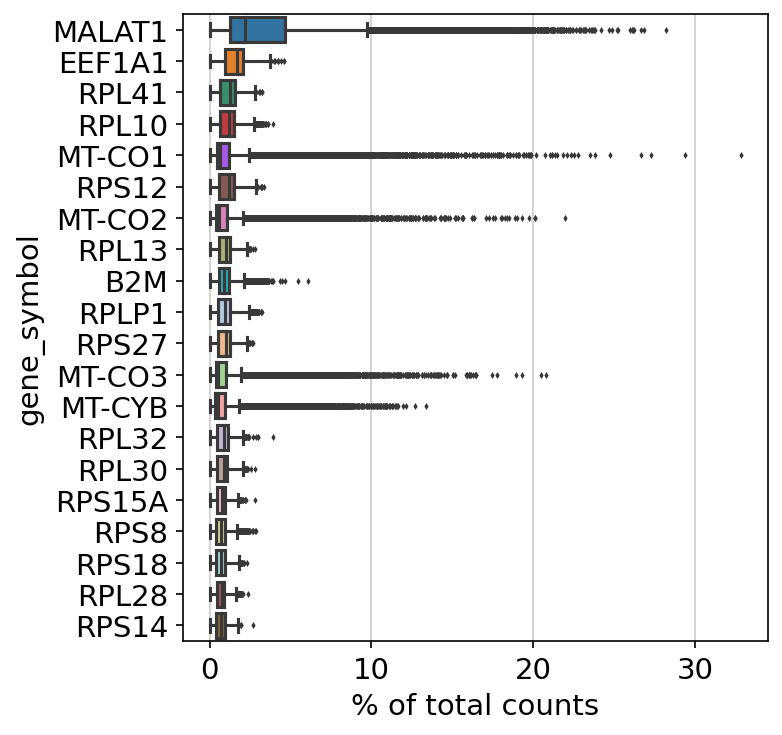

In [18]:
sc.pl.highest_expr_genes(adata3, n_top=20,save='Highest Expressed Genes it9.pdf')

# Filtros de QC

In [19]:
sc.pp.filter_cells(adata3, min_genes=700) #Best practice in sc paper pone 700 genes como minimo


filtered out 18620 cells that have less than 700 genes expressed


In [20]:
df_counts_CC ['cell_filter'] = adata3.obs['condition'].value_counts()
df_samples_counts['cell_filter'] = adata3.obs['sample'].value_counts()

In [21]:
#Filtro de genes
sc.pp.filter_genes(adata3, min_cells=5) #Best practice in sc paper pone 20 cells como minimo
df_samples_counts['gene_1_filter'] = adata3.obs['sample'].value_counts()
df_samples_counts['gene_1_filter'] = adata3.obs['condition'].value_counts()

filtered out 14773 genes that are detected in less than 5 cells


In [22]:
adata3.var["percent_mito"] = adata3.var_names.str.startswith("MT-")

In [23]:
sc.pp.calculate_qc_metrics(
    adata3, qc_vars=["percent_mito"], percent_top=None, log1p=False, inplace=True
)

In [24]:
adata3

AnnData object with n_obs × n_vars = 112606 × 21828
    obs: 'sample', 'condition', 'Sample', 'ClinicalSubtype', 'SerologicalSubtype', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_percent_mito', 'pct_counts_percent_mito'
    var: 'gene_id', 'sc_type', 'n_cells', 'percent_mito', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

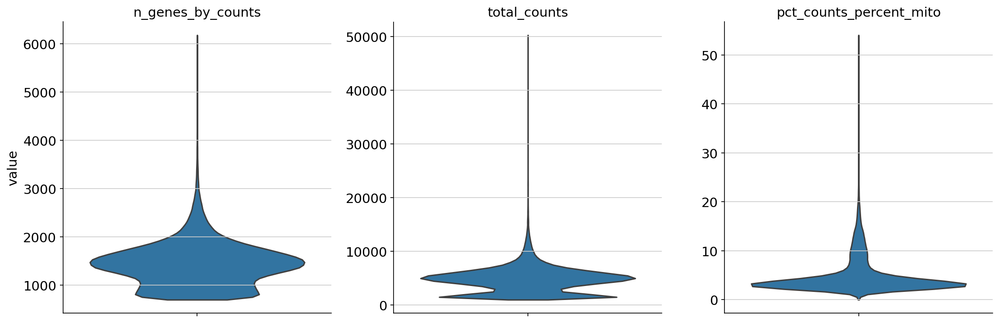

In [25]:
sc.pl.violin(
    adata3,
    ["n_genes_by_counts", "total_counts", "pct_counts_percent_mito"],
    jitter=0.4, multi_panel=True,stripplot=False
)

In [26]:
adata3.obs

,sample,condition,Sample,ClinicalSubtype,SerologicalSubtype,n_genes,n_genes_by_counts,total_counts,total_counts_percent_mito,pct_counts_percent_mito
AAACCTGAGAGATGAG,SSc2,SSc,SSc_2,lcSSc,ACA+,1882,1882,6583.0,249.0,3.782470
AAACCTGAGTATCTCG,SSc2,SSc,SSc_2,lcSSc,ACA+,2655,2654,8231.0,238.0,2.891508
AAACCTGAGTCACGCC,SSc2,SSc,SSc_2,lcSSc,ACA+,725,725,1126.0,127.0,11.278863
AAACCTGCAAACCCAT,SSc2,SSc,SSc_2,lcSSc,ACA+,1970,1970,7241.0,260.0,3.590664
AAACCTGCACAGACTT,SSc2,SSc,SSc_2,lcSSc,ACA+,1682,1682,5788.0,221.0,3.818244
...,...,...,...,...,...,...,...,...,...,...
TTTGTCAGTCAGCTAT,Ssc-C13,CTRL,CTRL_13,CTRL,CTRL,956,956,1661.0,244.0,14.689946
TTTGTCATCCATTCTA,Ssc-C13,CTRL,CTRL_13,CTRL,CTRL,1917,1917,6910.0,181.0,2.619392
TTTGTCATCCGTCATC,Ssc-C13,CTRL,CTRL_13,CTRL,CTRL,975,975,1715.0,228.0,13.294461
TTTGTCATCGGTTAAC,Ssc-C13,CTRL,CTRL_13,CTRL,CTRL,1326,1326,3438.0,261.0,7.591623


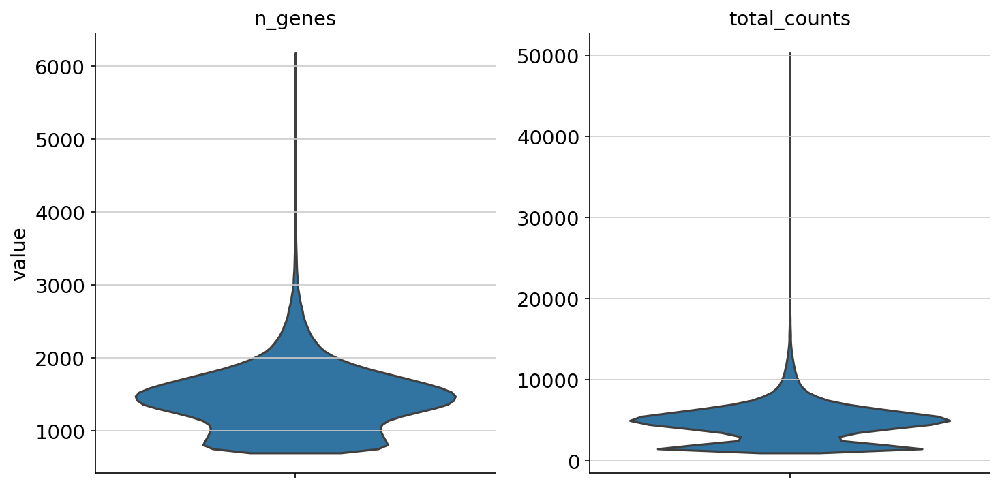

In [27]:

sc.pl.violin(adata3, ['n_genes', 'total_counts'],
             jitter=0.4, multi_panel=True,stripplot=False)

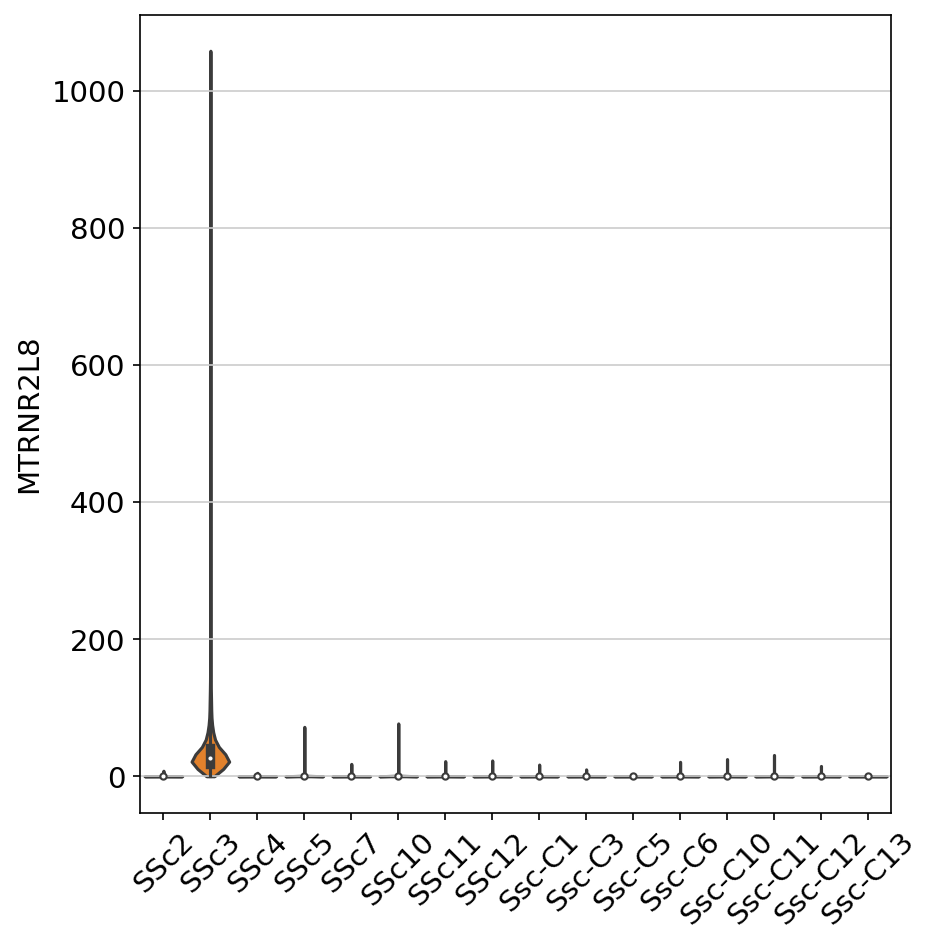

In [28]:
with rc_context({'figure.figsize': (6, 7)}):
    sc.pl.violin(adata3, [ 'MTRNR2L8'], groupby='sample', stripplot=False, inner='box',rotation=45)

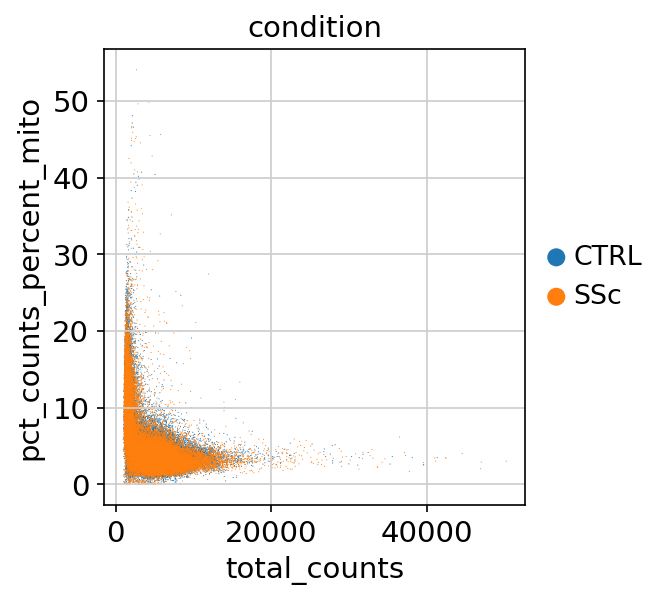

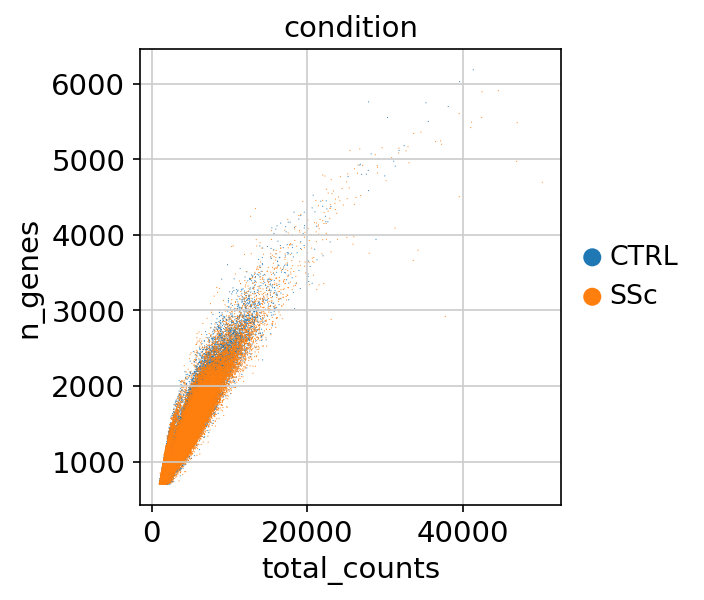

In [29]:
sc.pl.scatter(adata3, x='total_counts', y='pct_counts_percent_mito',color='condition')
sc.pl.scatter(adata3, x='total_counts', y='n_genes',color='condition')
#

In [30]:
print(adata3.obs['condition'].value_counts())

condition
SSc     58524
CTRL    54082
Name: count, dtype: int64


In [31]:
print('The cutoff for number of genes')
adata3 = adata3[adata3.obs.n_genes_by_counts < 2400, :]

#Remove cells that have too many mitochondrial Genes expressed and too many ribosomal Genes
print('The cutoff for percentage of mitochondrial genes is less than 7 Percent')
adata3 = adata3[adata3.obs.pct_counts_percent_mito < 7, :].copy()

#Remove MTRNR2L8 as artefact in sample SSc3
MTRNR2L8_rg = adata3[:, adata3.var.index == 'MTRNR2L8']
adata3 = adata3[:, ~adata3.var.index.isin(MTRNR2L8_rg.var.index)]


The cutoff for number of genes
The cutoff for percentage of mitochondrial genes is less than 7 Percent


In [32]:
adata3

View of AnnData object with n_obs × n_vars = 89467 × 21827
    obs: 'sample', 'condition', 'Sample', 'ClinicalSubtype', 'SerologicalSubtype', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_percent_mito', 'pct_counts_percent_mito'
    var: 'gene_id', 'sc_type', 'n_cells', 'percent_mito', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'sample_colors', 'condition_colors'

/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_utils.py:430: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


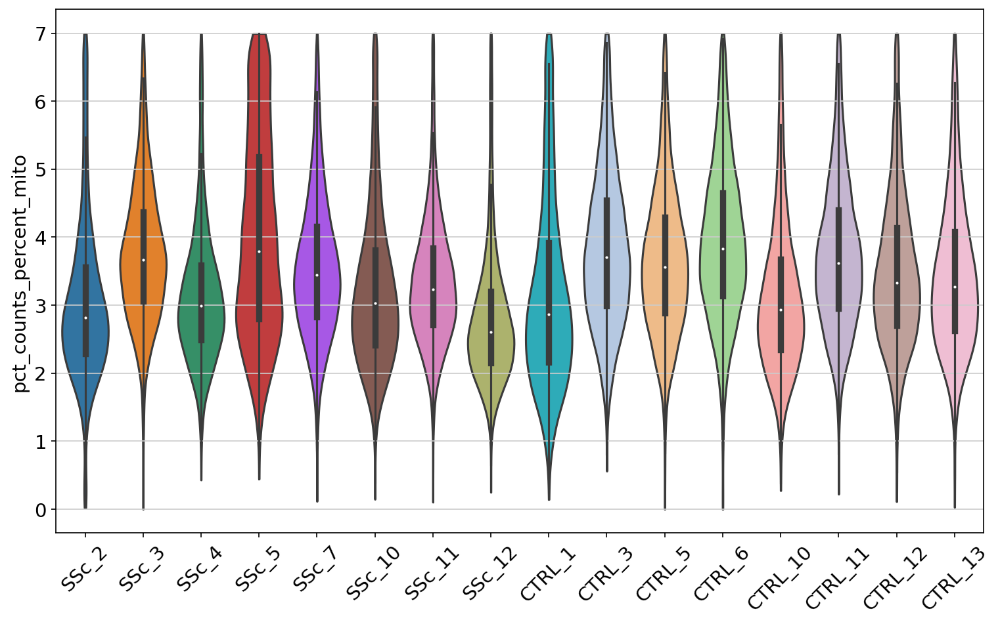

In [33]:
with rc_context({'figure.figsize': (10, 7)}):
    sc.pl.violin(adata3, [ 'pct_counts_percent_mito'], groupby='Sample', stripplot=False, inner='box', rotation =45)
#

In [34]:
# Data sets metrics

print(adata3.obs['condition'].value_counts())
print('')
print(adata3.obs['sample'].value_counts())
print('')
print(adata3.obs['sample'].value_counts('pct_counts_percent_mito'))
#

condition
SSc     45135
CTRL    44332
Name: count, dtype: int64

sample
SSc12      8744
SSc7       7571
SSc11      6866
Ssc-C3     6696
Ssc-C5     6617
SSc10      5983
Ssc-C11    5792
Ssc-C6     5761
Ssc-C13    5147
Ssc-C1     5144
Ssc-C10    4979
SSc3       4789
SSc2       4761
Ssc-C12    4196
SSc5       3508
SSc4       2913
Name: count, dtype: int64

sample
SSc12      0.097734
SSc7       0.084623
SSc11      0.076743
Ssc-C3     0.074843
Ssc-C5     0.073960
SSc10      0.066874
Ssc-C11    0.064739
Ssc-C6     0.064392
Ssc-C13    0.057530
Ssc-C1     0.057496
Ssc-C10    0.055652
SSc3       0.053528
SSc2       0.053215
Ssc-C12    0.046900
SSc5       0.039210
SSc4       0.032559
Name: proportion, dtype: float64


# Statistics 

In [35]:
adata3.layers["counts"] = adata3.X.copy() # preserve counts

In [36]:
#Normalizacion. Total-count normalize (library-size correct) the data matrix 𝐗 to 10,000 reads per cell,so that counts become comparable among cells.
sc.pp.normalize_total(adata3, target_sum=1e4) #El valor puede ser cambiado BPsc usa 1e6
sc.pp.log1p(adata3)

normalizing counts per cell
    finished (0:00:00)


In [37]:
adata3.raw = adata3

In [38]:
cc_genes = pd.read_table(cc_genes_file, delimiter='\t')

s_genes = cc_genes['S'].dropna()
g2m_genes = cc_genes['G2.M'].dropna()
s_genes_hs = adata3.var_names[np.in1d(adata3.var_names, s_genes)]
g2m_genes_hs = adata3.var_names[np.in1d(adata3.var_names, g2m_genes)]

sc.tl.score_genes_cell_cycle(adata3, s_genes_hs, g2m_genes_hs)

calculating cell cycle phase
computing score 'S_score'
    finished: added
    'S_score', score of gene set (adata.obs).
    2111 total control genes are used. (0:00:10)
computing score 'G2M_score'
    finished: added
    'G2M_score', score of gene set (adata.obs).
    2429 total control genes are used. (0:00:10)
-->     'phase', cell cycle phase (adata.obs)


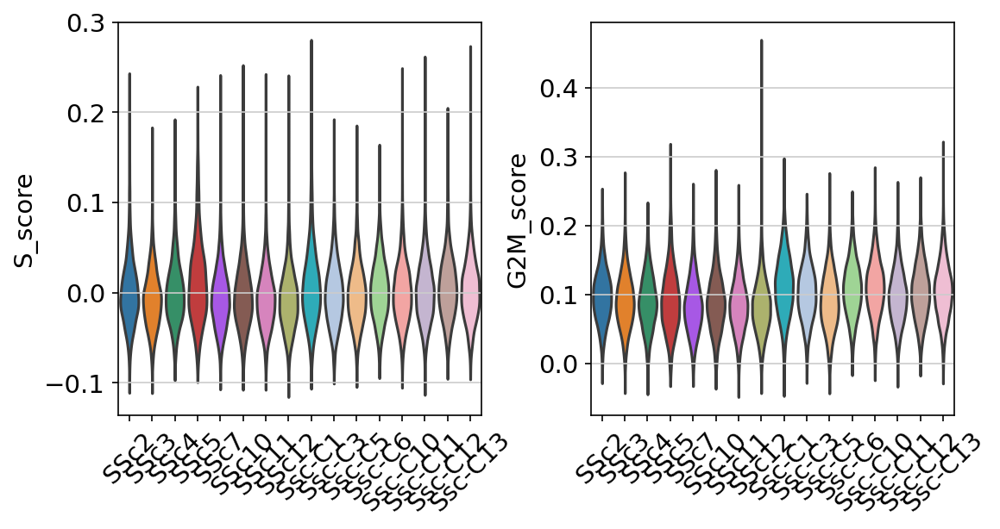

In [39]:
sc.pl.violin(adata3, ['S_score', 'G2M_score'],
             jitter=0.4, stripplot=False,groupby = 'sample', rotation=45)

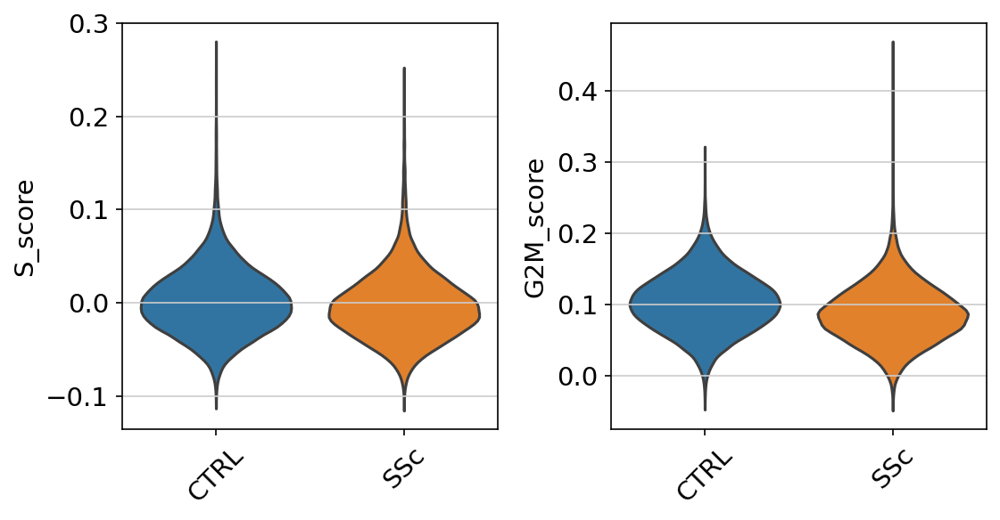

In [40]:
sc.pl.violin(adata3, ['S_score', 'G2M_score'],
             jitter=0.4, stripplot=False,groupby = 'condition', rotation=45)

If you pass `n_top_genes`, all cutoffs are ignored.
extracting highly variable genes
    finished (0:00:09)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
Highly variable genes: 1500


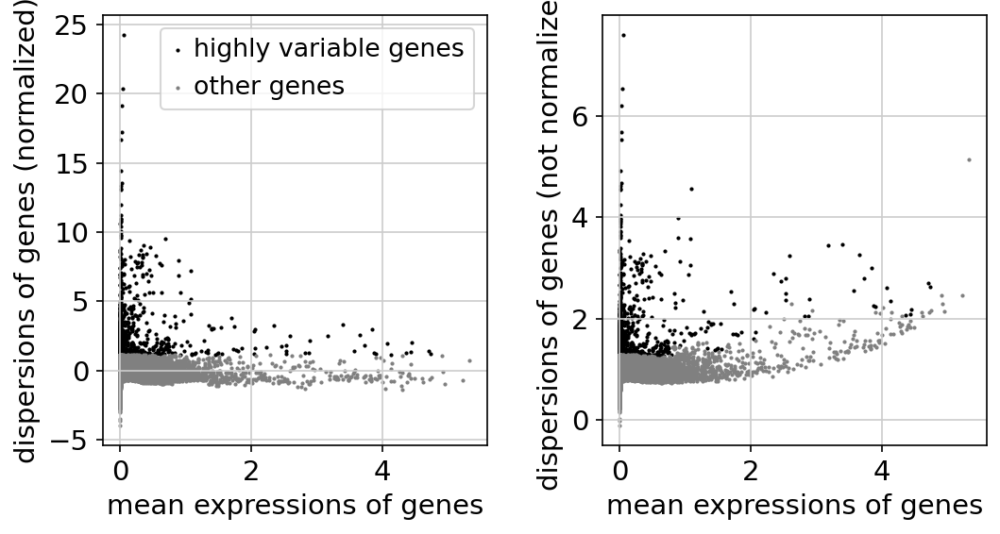

In [41]:
#Calculo de los HVG. 
sc.pp.highly_variable_genes(adata3, n_top_genes=1500)
print("Highly variable genes: %d"%sum(adata3.var.highly_variable))
sc.pl.highly_variable_genes(adata3)

In [42]:
#Filtering by HVG
adata3 = adata3[:, adata3.var.highly_variable]
#

In [43]:
sc.pp.regress_out(adata3, ['total_counts','pct_counts_percent_mito','S_score', 'G2M_score']) 
#

regressing out ['total_counts', 'pct_counts_percent_mito', 'S_score', 'G2M_score']
    finished (0:02:39)


In [44]:
sc.pp.scale(adata3, max_value=10)

# Principal Component Analysis

In [45]:
#PCA and neighbors
sc.tl.pca(adata3, n_comps=50,svd_solver='arpack')

computing PCA
    on highly variable genes
    with n_comps=50
    finished (0:00:29)


/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


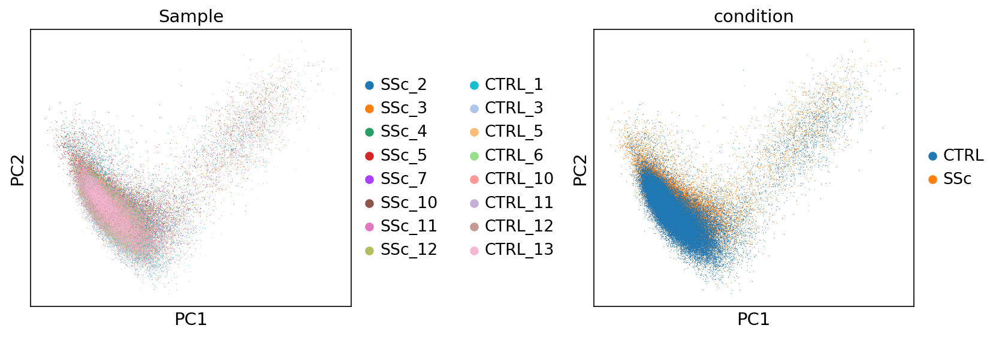

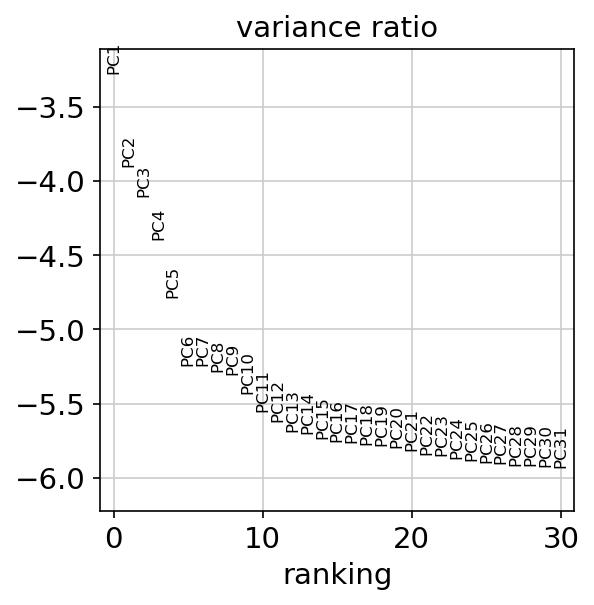

In [46]:
sc.pl.pca(adata3,color = ['Sample','condition'],wspace=0.6,save='PCA_it91.png')
sc.pl.pca_variance_ratio(adata3, log=True)

/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


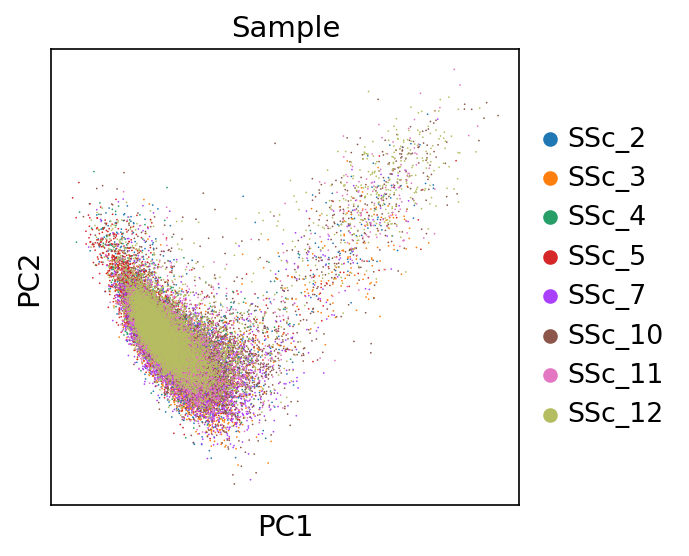

In [47]:
sc.pl.pca(adata3[adata3.obs['condition']=='SSc'],color = ['Sample'],wspace=0.6)

/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


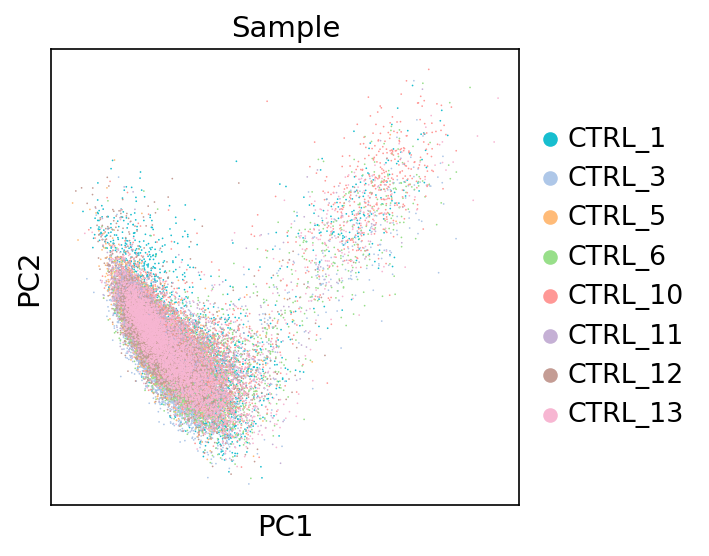

In [48]:
sc.pl.pca(adata3[adata3.obs['condition']=='CTRL'],color = ['Sample'],wspace=0.6)

# Batch correction

sce.pp.harmony_integrate(adata3,key='sample')
print('Batch Correction by Harmony')

sc.pp.neighbors(adata3, use_rep = 'X_pca_harmony')

In [49]:
#BBKNN Batch Balanced K-Nearest Neighbour 
#Corrects the knn graph
#Enter the Number of PC's from the Elbow Plot
sce.pp.bbknn(adata3,batch_key='sample',n_pcs=20)
print('Batch Correction by BBKNN')


computing batch balanced neighbors
	finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:29)
Batch Correction by BBKNN


# Dimensionality reduction and clustering

In [50]:
#Dimensionality reduction
sc.tl.umap(adata3)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:02:16)


/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:369: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:379: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:369: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:379: UserWa

/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


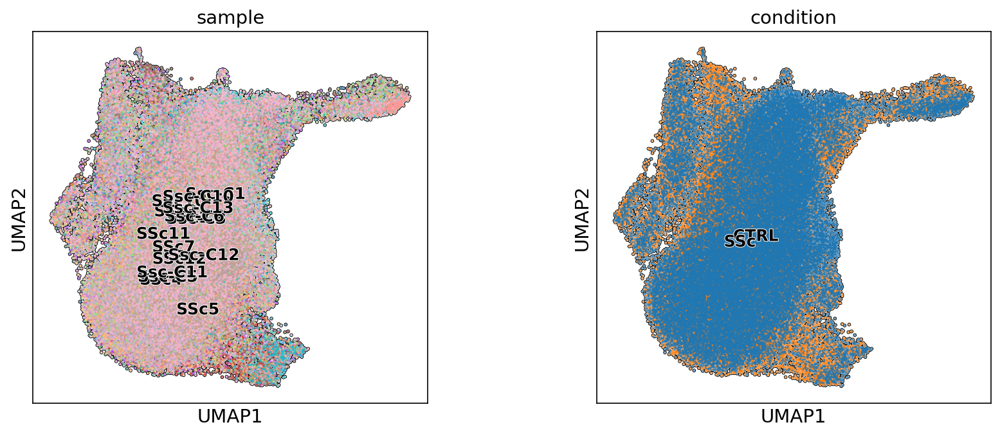

In [51]:
#Visualization (UMAP) && Clustering {Leiden&Louvain}
with rc_context({'figure.figsize': (5, 5)}):
    sc.pl.umap(adata3, color = ['sample','condition'], add_outline=True, legend_loc='on data',
               legend_fontsize=12, legend_fontoutline=1,frameon=True, wspace=0.3,size=10)

In [51]:
sc.tl.embedding_density(adata3, basis='umap', groupby='condition')
#

computing density on 'umap'
--> added
    'umap_density_condition', densities (adata.obs)
    'umap_density_condition_params', parameter (adata.uns)


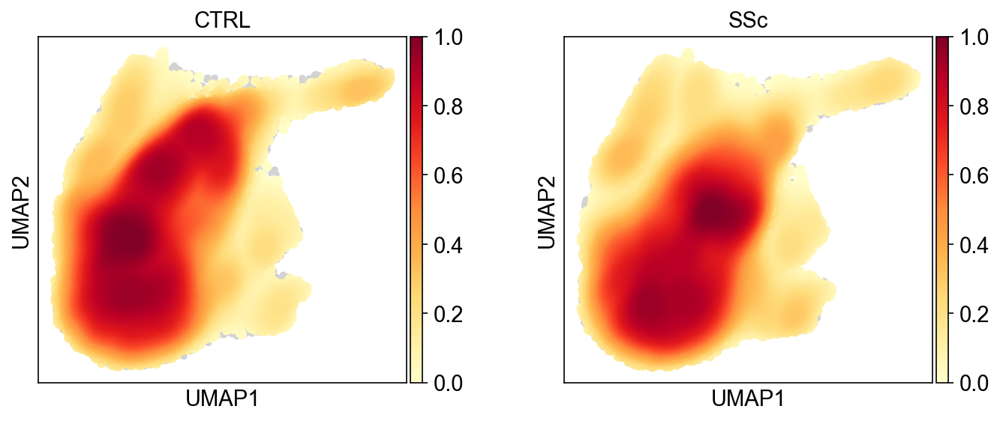

In [52]:
sc.pl.embedding_density(adata3,  groupby='condition', wspace=0.3)
#

In [52]:
#clustering
sc.tl.leiden(adata3,1)

running Leiden clustering


IOStream.flush timed out
IOStream.flush timed out


    finished: found 14 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:04:36)


/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:369: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:379: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


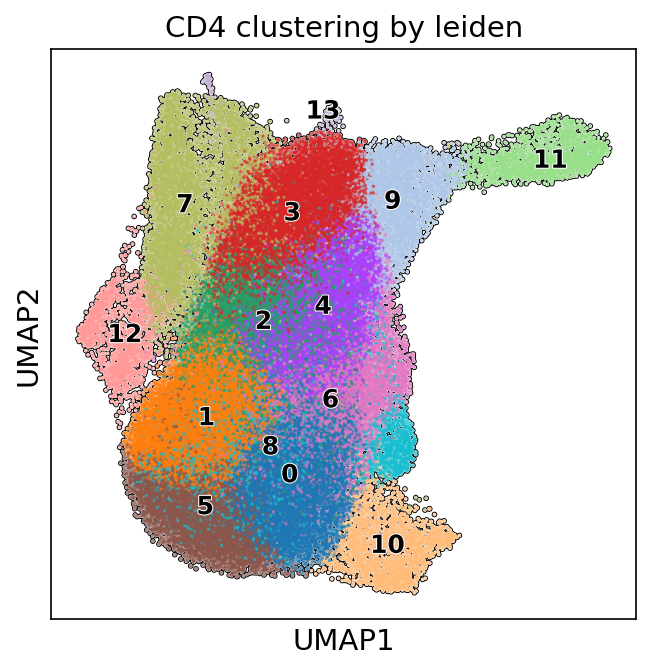

In [53]:
#Visualization (UMAP) && Clustering {Leiden&Louvain}
with rc_context({'figure.figsize': (5, 5)}):
    sc.pl.umap(adata3, color = ['leiden'], add_outline=True, legend_loc='on data',
               legend_fontsize=12, legend_fontoutline=1,frameon=True, wspace=0.3,size=10,
               title=['CD4 clustering by leiden'],save='scRNAseq_CD4_SSc_leidenR1_it91.png')


/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:369: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:379: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(


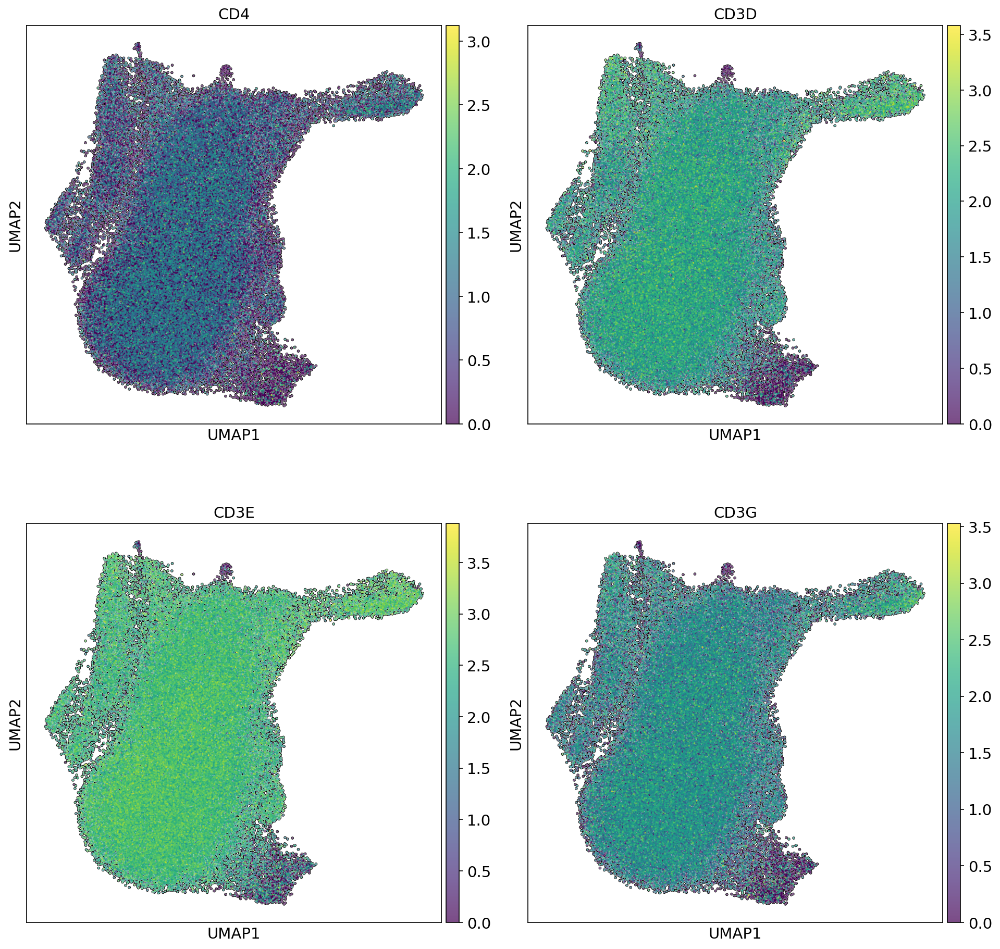

In [54]:
with rc_context({'figure.figsize': (7, 7)}):
    sc.pl.umap(adata3, color = ['CD4','CD3D','CD3E','CD3G'],ncols=2 ,add_outline=True, legend_loc='on data',
               size=10,legend_fontsize=12, legend_fontoutline=1,frameon=True, wspace=0.1)

/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:369: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:379: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(


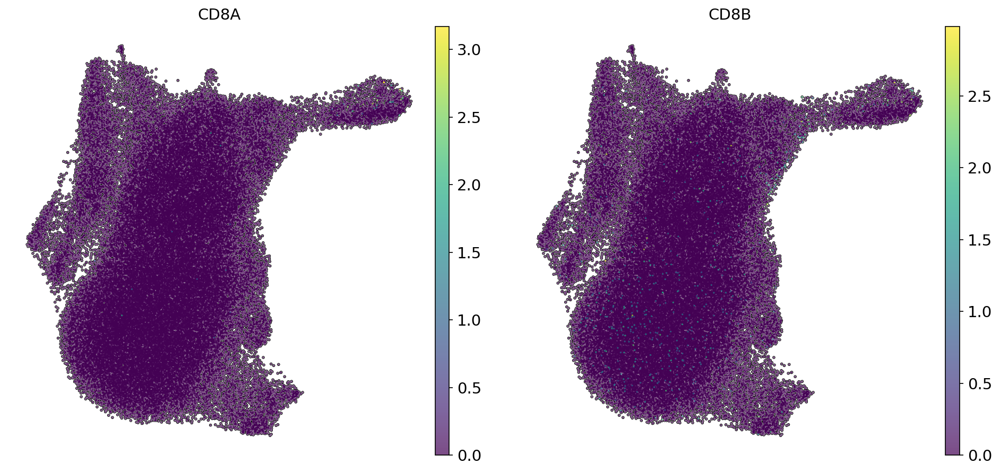

In [55]:
with rc_context({'figure.figsize': (7, 7)}):
    sc.pl.umap(adata3, color = ['CD8A','CD8B'], add_outline=True, legend_loc='on data',
               size=10,legend_fontsize=12, legend_fontoutline=1,frameon=False, wspace=0.1)

/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:369: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:379: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(


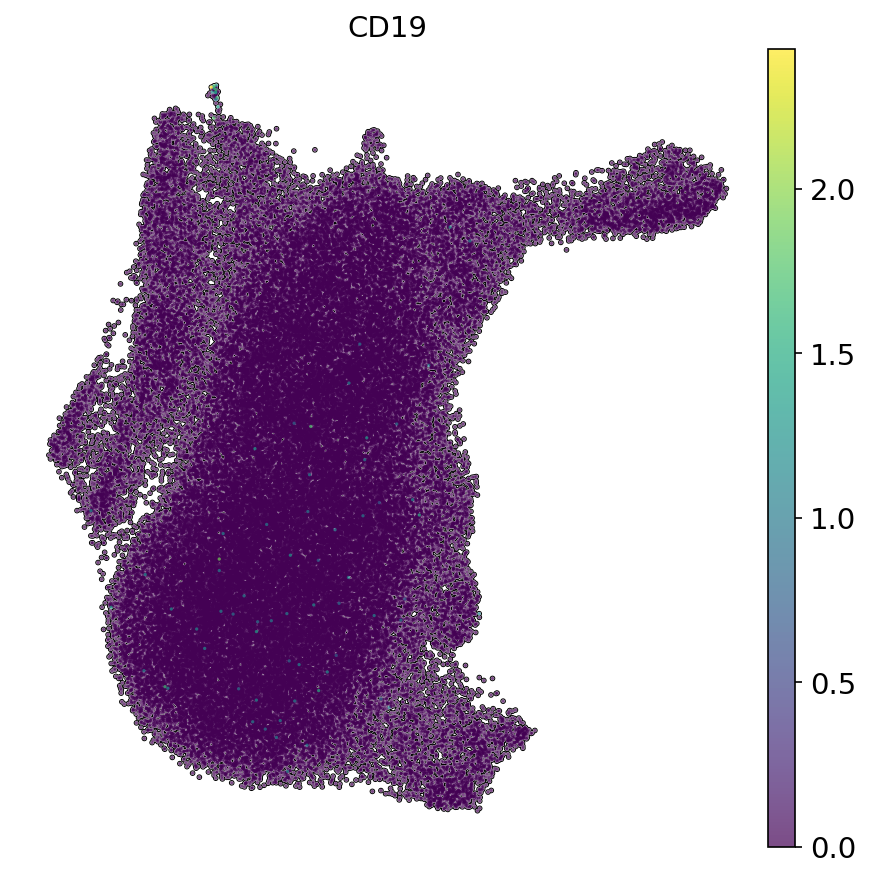

In [56]:
with rc_context({'figure.figsize': (7, 7)}):
    sc.pl.umap(adata3, color = ['CD19'], add_outline=True, legend_loc='on data',
               size=10,legend_fontsize=12, legend_fontoutline=1,frameon=False, wspace=0.1)

/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:369: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:379: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(


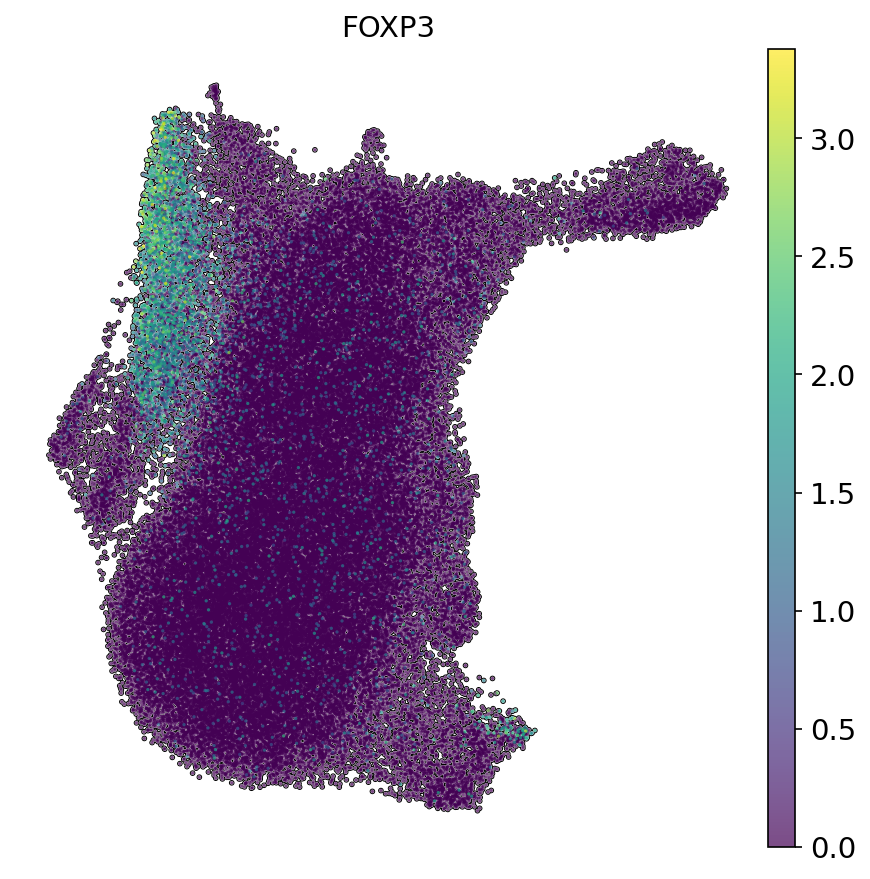

In [57]:
with rc_context({'figure.figsize': (7, 7)}):
    sc.pl.umap(adata3, color = ['FOXP3'], add_outline=True, legend_loc='on data',
               size=10,legend_fontsize=12, legend_fontoutline=1,frameon=False, wspace=0.1)

/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:369: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:379: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(


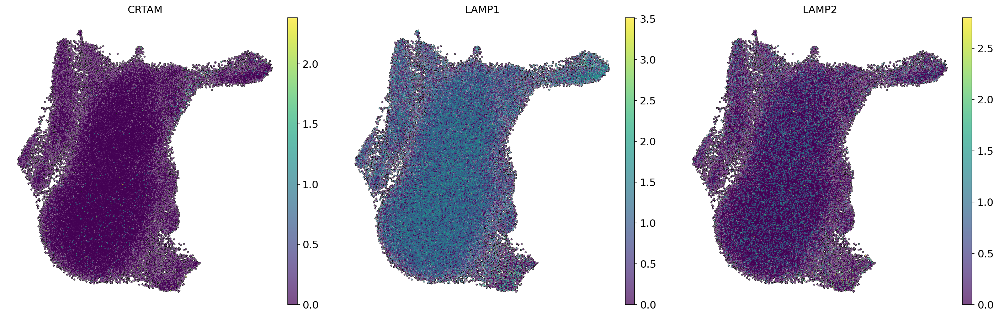

In [58]:
with rc_context({'figure.figsize': (7, 7)}):
    sc.pl.umap(adata3, color = ['CRTAM','LAMP1','LAMP2'], add_outline=True, legend_loc='on data',
               size=10,legend_fontsize=12, legend_fontoutline=1,frameon=False, wspace=0.1)

/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:369: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:379: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(


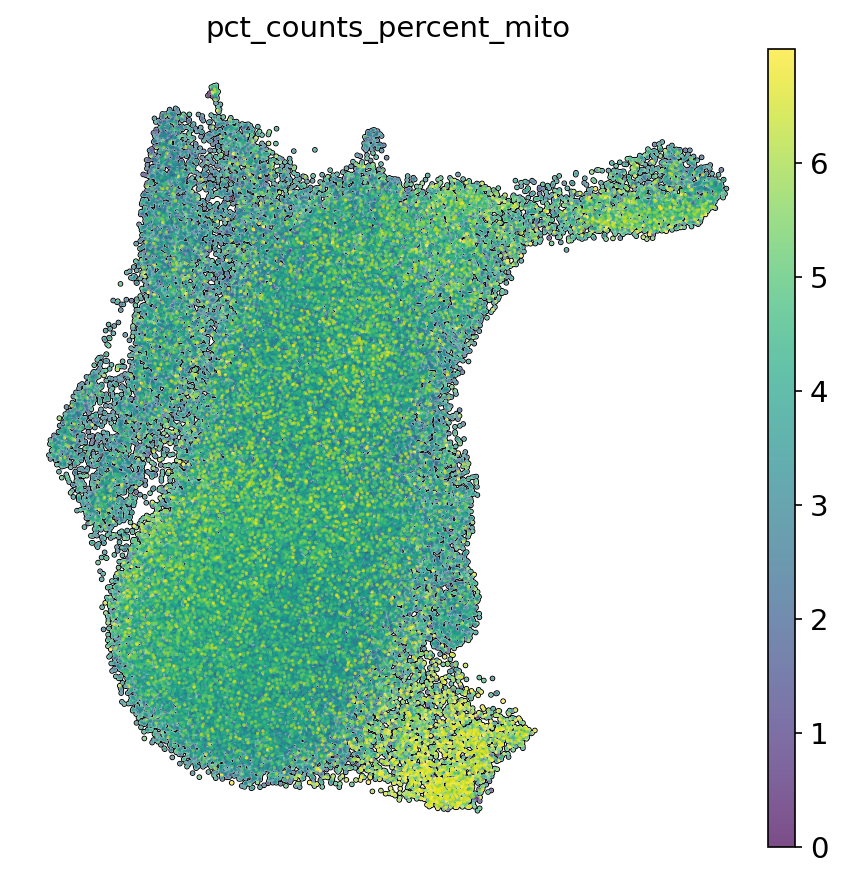

In [59]:
with rc_context({'figure.figsize': (7, 7)}):
    sc.pl.umap(adata3, color = ['pct_counts_percent_mito'], add_outline=True, legend_loc='on data',
               size=10,legend_fontsize=12, legend_fontoutline=1,frameon=False, wspace=0.1)

In [60]:
# Annotate the data sets
print(adata3.obs['condition'].value_counts())
print('')
print(adata3.obs['sample'].value_counts())
print('')
print(adata3.obs['leiden'].value_counts())
print('')

condition
SSc     45135
CTRL    44332
Name: count, dtype: int64

sample
SSc12      8744
SSc7       7571
SSc11      6866
Ssc-C3     6696
Ssc-C5     6617
SSc10      5983
Ssc-C11    5792
Ssc-C6     5761
Ssc-C13    5147
Ssc-C1     5144
Ssc-C10    4979
SSc3       4789
SSc2       4761
Ssc-C12    4196
SSc5       3508
SSc4       2913
Name: count, dtype: int64

leiden
0     10750
1     10282
2     10231
3     10041
4      9322
5      8587
6      7378
7      6768
8      4566
9      4351
10     2648
11     2379
12     2032
13      132
Name: count, dtype: int64



In [61]:
pd.crosstab(adata3.obs['Sample'], adata3.obs['leiden'])

leiden,0,1,2,3,4,5,6,7,8,9,10,11,12,13
Sample,,,,,,,,,,,,,,
SSc_2,621,357,826,466,681,270,169,520,220,197,238,92,96,8
SSc_3,428,588,835,866,369,397,250,376,225,156,21,132,141,5
SSc_4,414,328,371,210,111,615,167,269,173,95,86,9,61,4
SSc_5,630,155,471,158,206,581,293,79,118,51,641,48,74,3
SSc_7,951,1112,852,614,720,907,525,531,429,539,107,79,188,17
SSc_10,506,471,963,728,343,558,335,690,137,628,207,283,125,9
SSc_11,515,825,1232,825,418,985,574,597,311,162,77,140,197,8
SSc_12,1403,910,1287,469,544,1012,888,622,406,354,316,332,197,4
CTRL_1,428,243,361,1195,732,118,521,356,175,288,478,171,73,5


# Preliminar annotation

In [75]:
predictions2 = celltypist.annotate(adata3, model = 'Immune_Blood_Low.pkl', majority_voting = True)

NameError: name 'celltypist' is not defined

In [ ]:
adata4 = predictions2.to_adata()

In [ ]:
with rc_context({'figure.figsize': (4, 4)}):
    sc.pl.umap(adata4, color=['majority_voting','predicted_labels'], add_outline=True,
               legend_fontsize=12, legend_fontoutline=1,frameon=False,size=5,
               palette='Set1', wspace=0.5,save='scRNAseq_CD4_SSc_CellTypist_it91.png')

sc.tl.rank_genes_groups(adata3, 'majority_voting', method='wilcoxon', key_added='Majority_wilcoxon')
sc.pl.rank_genes_groups(adata3, n_genes=15, sharey=False, key='Majority_wilcoxon')

In [ ]:
#Guardamos en listas los barcodes de las celulas que pertenecen a esos clusters para eliminarlos mas adelante

#Granulocytes = list(adata3[adata3.obs['majority_voting']=='Granulocytes'].obs.index)

Bcells = list(adata4[adata4.obs['majority_voting']=='B cells'].obs.index)
NKcells = list(adata4[adata4.obs['majority_voting']=='NK cells'].obs.index)

CD4_rogueCelltypist= list(Bcells+NKcells)

In [ ]:
#CD4_rogueCelltypist

In [ ]:
import json
with open('/project/csic_granada/Single.cell_analysis/CellsToRemoveCD4_it9.txt', 'w') as f:
    f.write(json.dumps(CD4_rogueCelltypist))

#Guardamos en listas los barcodes de las celulas que pertenecen a esos clusters para eliminarlos mas adelante

Granulocytes = list(adata3[adata3.obs['majority_voting']=='Granulocytes'].obs.index)

CD4_rogue_cell= list(Bcells+ NKcells+Granulocytes)

In [64]:
####Distribution of some known markers
all_markers = dict()

##CD8:
#CD8 memory T cell: CD3, CD8, CD45RO (PTPRC), TCRa/b
#CTL: CD3, CD8, GZMA, GZMB, TCRa/b

all_markers['CTL']=['CD3D', 'CD8A', 'CD8B', 'GZMA', 'GZMB']
all_markers['CD8 memory T cell']=['CD3D', 'CD8A', 'CD8B', 'GZMA', 'GZMB'] 
##NKT: CD1d, CD2, CD3, CD94 (KLRD1), CD160, KLRG1, TCRa/b, ZAP70
all_markers['NKT']=['CD3D', 'CD8A', 'CD8B', 'CD1D', 'CD2', 'KLRD1', 'CD160', 'KLRG1','ZAP70']       
##Gamma-delta T cells: CD3, CD4, CD8, TCRg/d
all_markers['Gamma-delta T cells']=['CD3D', 'CD8A', 'CD8B', 'CD4', 'TRGC1', 'TRGC2','TRDC', 
                                    'TRAC', 'TRBC1', 'TRBC2']            
####B cell: CD19, CD24, CD72, CD40
all_markers['B cell']=['CD19', 'CD24', 'CD72', 'CD40']          
#Mature B cells: CD20 (MS4A1), CD21 (CR2), CD22
all_markers['Mature B cells']=['CD19', 'MS4A1', 'CR2', 'CD22']           
#Activated B cells: CD23 (ITGB1)
all_markers['Activated B cells']=['CD19', 'ITGB1']          
#Memory: CD20, CD27, CD80, CD84, CD86
all_markers['Memory']=['CD19', 'CD20', 'CD27', 'CD80', 'CD84', 'CD86']         
#Surface Ig+ B cells: CD79a,b
all_markers['Surface Ig+ B cells']=['CD19', 'CD79A', 'CD79B']        
#Plasma cells: CD138 (SDC1), CD126 (IL6R), CD319 (SLAMF7), CD78, BCMA (TNFRSF17)
all_markers['Plasma cells']=['CD19', 'IL6R', 'SLAMF7', 'TNFRSF17']

In [65]:
# Apoptotic markers ,'APOC2'
with rc_context({'figure.figsize': (10, 7)}):
    sc.pl.violin(adata4,['TP53','AIFM1','BCL2','MALAT1'], groupby='leiden', stripplot=False, inner='box')
#

NameError: name 'adata4' is not defined

In [ ]:
# Apoptotic (2) 
with rc_context({'figure.figsize': (10, 7)}):
    sc.pl.violin(adata4,['XIAP','MCL1','BID'], groupby='leiden', stripplot=False, inner='box')
    #

In [ ]:
##CD8
with rc_context({'figure.figsize': (10, 7)}):
    sc.pl.violin(adata4, all_markers['CTL'], groupby='leiden', stripplot=False, inner='box')


In [ ]:
with rc_context({'figure.figsize': (10, 7)}):
    sc.pl.violin(adata4, all_markers['CD8 memory T cell'], groupby='leiden', stripplot=False, inner='box')


In [ ]:
##NKT:
with rc_context({'figure.figsize': (10, 7)}):
    sc.pl.violin(adata4, all_markers['NKT'], groupby='leiden', stripplot=False, inner='box')
    

In [ ]:
#Gamma-delta T cells
with rc_context({'figure.figsize': (10, 7)}):
    sc.pl.violin(adata4, all_markers['Gamma-delta T cells'], groupby='leiden', stripplot=False, inner='box')
    

In [ ]:
#B cell
with rc_context({'figure.figsize': (10, 7)}):
    sc.pl.violin(adata4, all_markers['B cell'], groupby='leiden', stripplot=False, inner='box')


In [73]:
adata3.layers['scaled'] = sc.pp.scale(adata3, copy=True).X

In [66]:
Soskic_makers = dict()
 
#
Soskic_makers['Tn']= ['CCR7','LRRN3','FHIT','SELL']
#
Soskic_makers['Tcm']= ['CREM','ITGB1','KLRB1']
#
Soskic_makers['Tem']= ['LYAR','S100A4','S100A6']
#
Soskic_makers['Temra']=['CCL5','NKG7','GNLY','GZMH','GZMB']
#
Soskic_makers['nTreg']=['TIGIT','FOXP3','IKZF2','IL2RA']
#

    using 'X_pca' with n_pcs = 50
Storing dendrogram info using `.uns['dendrogram_leiden']`
categories: 0, 1, 2, etc.
var_group_labels: Tn, Tcm, Tem, etc.


/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:749: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


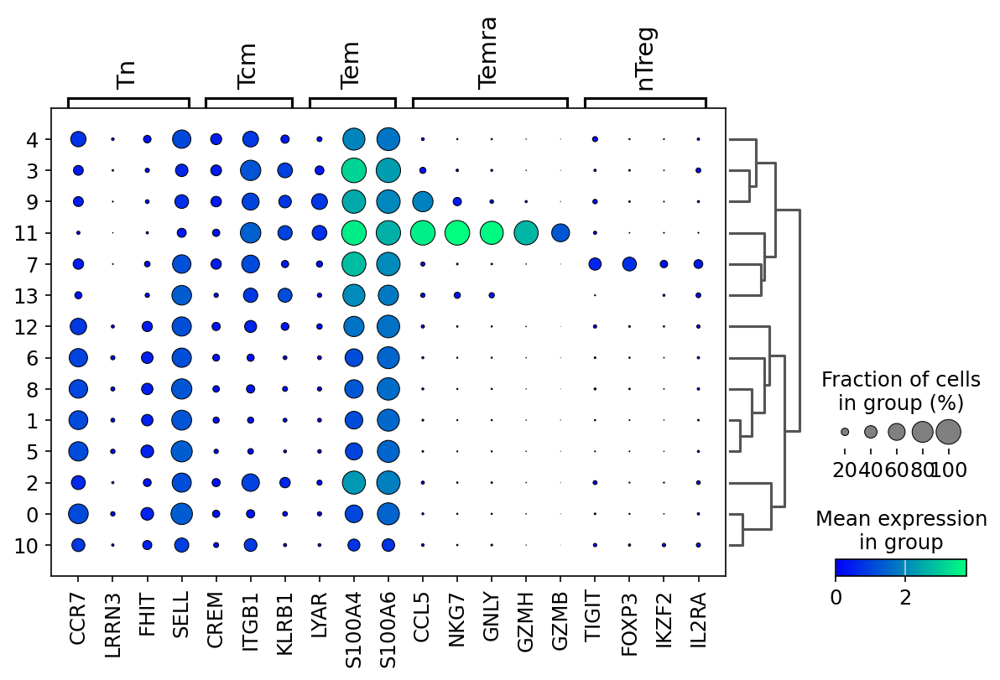

In [67]:
dp=sc.pl.dotplot(adata3, Soskic_makers, 'leiden',return_fig=True, dendrogram=True) # ,dendrogram = True si incluyo esto agrupa
dp.style(dot_edge_color='black', dot_edge_lw=0.5).show()

In [68]:
cluster2annotation3 = {
     '0': 'Tn',
     '1': 'Tn',
     '2': 'Tn',
     '3': 'Tn',
     '4': 'Tcm',
     '5': 'Tcm',
     '6': 'Tem',
     '7': 'Temra',
     '8': 'CTL', 
     '9': 'Tn',
    '10':'Treg',
    '11':'Tn',
    '12':'Temra',
    '13':'CTL'

}
adata3.obs['cell_type'] = adata3.obs['leiden'].map(cluster2annotation3).astype('category')
#
Soskic_pallet = {
         'Tn': '#a9dfbb',
         'Tcm': '#6cd0c4',
         'Treg': '#fc6daf',
         'Tem': '#3faccd',
         'Temra': '#176fb7',
        'CTL':'red'
     }

/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:369: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:379: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


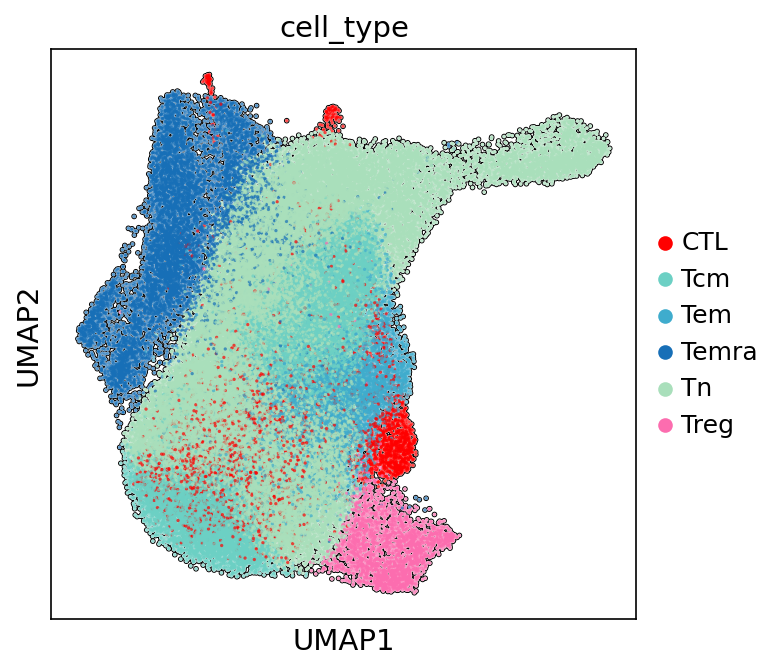

In [69]:
#Visualization (UMAP) && Clustering {Leiden&Louvain}
with rc_context({'figure.figsize': (5, 5)}):
    sc.pl.umap(adata3, color = ['cell_type'], add_outline=True,
               legend_fontsize=12, legend_fontoutline=1,frameon=True, wspace=0.3,size=10,
              palette= Soskic_pallet)

/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:369: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:379: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


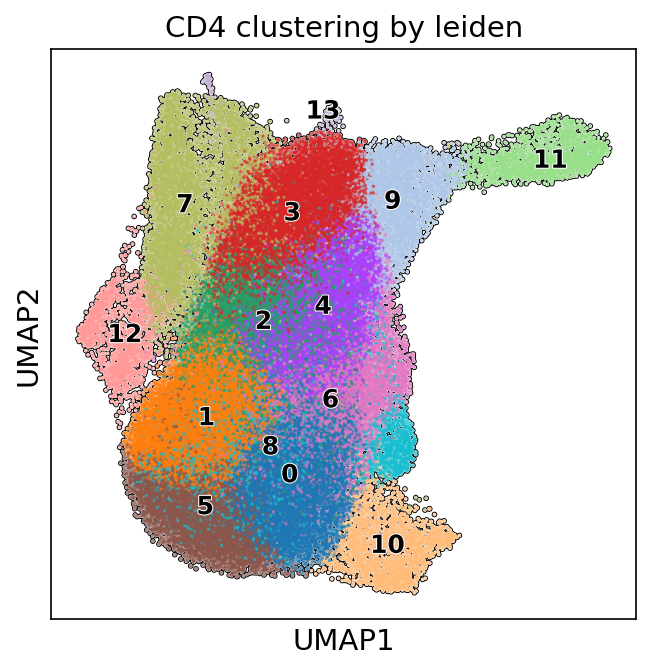

In [70]:
with rc_context({'figure.figsize': (5, 5)}):
    sc.pl.umap(adata3, color = ['leiden'], add_outline=True, legend_loc='on data',
               legend_fontsize=12, legend_fontoutline=1,frameon=True, wspace=0.3,size=10,
               title=['CD4 clustering by leiden'])


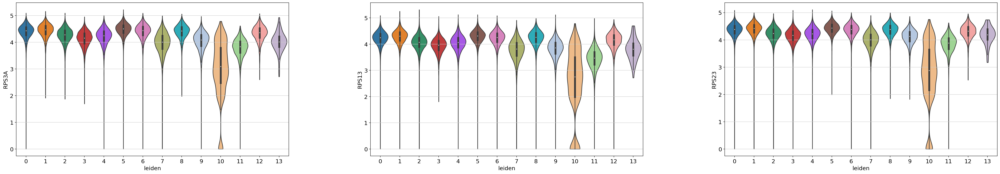

In [71]:
# 
with rc_context({'figure.figsize': (10, 7)}):
    sc.pl.violin(adata3,['RPS3A','RPS13','RPS23'], groupby='leiden', stripplot=False, inner='box')
#

/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:369: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/home/ch258010/miniconda3/envs/condaScanpy/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:379: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(


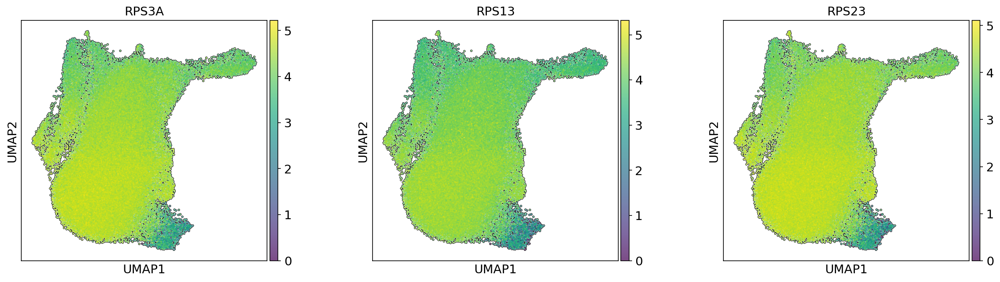

In [72]:
#Visualization (UMAP) && Clustering {Leiden&Louvain}
with rc_context({'figure.figsize': (5, 5)}):
    sc.pl.umap(adata3, color = ['RPS3A','RPS13','RPS23'], add_outline=True, legend_loc='on data',
               legend_fontsize=12, legend_fontoutline=1,frameon=True, wspace=0.3,size=10)

# Restart removing no CD4+ cells

In [74]:
del(adata)
#del(adata_it9)
del(adata3)
#del(adata4)

In [79]:
#Data files 
sample_strings = ['SSc2','SSc3','SSc4','SSc5','SSc7','SSc10','SSc11','SSc12','Ssc-C1','Ssc-C3','Ssc-C5','Ssc-C6','Ssc-C10','Ssc-C11','Ssc-C12','Ssc-C13'] #el id original de la muestra 
sample_id_strings = ['63-2','64-2','65-2','66-2','67-2','68-2','69-2','70-2','71-2','72-2','73-2','74-2','75-2','76-2','77-2','78-2'] #el run del CellRanger a la hora de procesarlos
file_base = '../molgen/CR_outs/cr-count_ext_L232' 
file_base = '../molgen/CR_outs/cr-count_hg38_ext_L226' 
exp_string = '-GEX_files/filtered_feature_bc_matrix/' 
data_file_end = 'matrix.mtx.gz' 
barcode_file_end = 'barcodes.tsv.gz' 
gene_file_end = 'features.tsv.gz' 
cc_genes_file = '../analysis/support_files/cc_gene_list.txt' #lista de genes del ciclo celular
CD4_Rogue_cells = '../analysis/support_files/CellsToRemoveCD4.txt'
#

In [80]:
#TCR files
TCR_sample_strings = ['SSc2-TCR','SSc3-TCR','SSc4-TCR','SSc5-TCR','SSc7-TCR','SSc10-TCR','SSc11-TCR','SSc12-TCR','Ssc-C1-TCR','Ssc-C3-TCR','Ssc-C5-TCR','Ssc-C6-TCR','Ssc-C10-TCR','Ssc-C11-TCR','Ssc-C12-TCR','Ssc-C13-TCR'] #el id original de la muestra
TCR_sample_id_strings = ['63-1','64-1','65-1','66-1','67-1','68-1','69-1','70-1','71-1','72-1','73-1','74-1','75-1','76-1','77-1','78-1'] #el run del CellRanger a la hora de procesarlosfile_base = '/project/csic_granada/Single.cell_analysis/00_SSc_CD14/cr-count_ext_L232'
TCR_file_base = '../molgen/CR_outs/cr-vdj_hg38_ext_L226'
TCR_exp_string = '_files/outs/'
TCR_csv_file = 'filtered_contig_annotations.csv'

In [82]:
#First data set load & annotation
#Parse Filenames
sample = sample_strings.pop(0)
sample
sample_id = sample_id_strings.pop(0)
data_file = file_base+sample_id+'_'+sample+exp_string+data_file_end
barcode_file = file_base+sample_id+'_'+sample+exp_string+barcode_file_end
gene_file = file_base+sample_id+'_'+sample+exp_string+gene_file_end

#Load data
adata = sc.read(data_file, cache=True)
adata = adata.transpose()
adata.X = adata.X.toarray()

barcodes = pd.read_csv(barcode_file, header=None, sep='\t')
genes = pd.read_csv(gene_file, header=None, sep='\t')

#Annotate data
barcodes.rename(columns={0:'barcode'}, inplace=True)
barcodes.set_index('barcode', inplace=True)
adata.obs = barcodes
adata.obs['sample'] = [sample]*adata.n_obs
if '-C' in sample:
    adata.obs['condition'] = ['CTRL']*adata.n_obs
else:
    adata.obs['condition'] = ['SSc']*adata.n_obs

genes.rename(columns={0:'gene_id', 1:'gene_symbol', 2:'sc_type'}, inplace=True)
genes.set_index('gene_symbol', inplace=True)
adata.var = genes
adata.var_names_make_unique()

... reading from cache file cache/..-molgen-CR_outs-cr-count_hg38_ext_L22663-2_SSc2-GEX_files-filtered_feature_bc_matrix-matrix.h5ad


In [84]:
TCR_data_file

'../molgen/CR_outs/cr-vdj_hg38_ext_L22663-1_SSc2-TCR_files/outs/filtered_contig_annotations.csv'

In [85]:
adata

AnnData object with n_obs × n_vars = 7193 × 36601
    obs: 'sample', 'condition'
    var: 'gene_id', 'sc_type'

In [86]:
TCR_sample = TCR_sample_strings.pop(0)
TCR_sample
TCR_sample_id = TCR_sample_id_strings.pop(0)
TCR_data_file = TCR_file_base+TCR_sample_id+'_'+TCR_sample+TCR_exp_string+TCR_csv_file
adata_tcr = ir.io.read_10x_vdj(TCR_data_file)
adata_tcr.shape
mdata = MuData({"airr": adata_airr, "gex": adata_gex})

NameError: name 'MuData' is not defined

In [ ]:
adata_airr = ir.io.read_10x_vdj("all_contig_annotations.json")
adata_gex = sc.read_10x_h5("filtered_feature_bc_matrix.h5")
mdata = MuData({"airr": adata_airr, "gex": adata_gex})

adata.obs

In [ ]:
# Loop to load rest of data sets
for i in range(len(sample_strings)):
    #Parse Filenames
    sample = sample_strings[i]
    sample_id = sample_id_strings[i]
    data_file = file_base+sample_id+'_'+sample+exp_string+data_file_end
    barcode_file = file_base+sample_id+'_'+sample+exp_string+barcode_file_end
    gene_file = file_base+sample_id+'_'+sample+exp_string+gene_file_end
    
    #Load data
    adata_tmp = sc.read(data_file, cache=True)
    adata_tmp = adata_tmp.transpose()
    adata_tmp.X = adata_tmp.X.toarray()

    barcodes_tmp = pd.read_csv(barcode_file, header=None, sep='\t')
    genes_tmp = pd.read_csv(gene_file, header=None, sep='\t')
    
    #Annotate data
    barcodes_tmp.rename(columns={0:'barcode'}, inplace=True)
    barcodes_tmp.set_index('barcode', inplace=True)
    adata_tmp.obs = barcodes_tmp
    adata_tmp.obs['sample'] = [sample]*adata_tmp.n_obs
    if '-C' in sample:
        adata_tmp.obs['condition'] = ['CTRL']*adata_tmp.n_obs
    else:
        adata_tmp.obs['condition'] = ['SSc']*adata_tmp.n_obs
    
    genes_tmp.rename(columns={0:'gene_id', 1:'gene_symbol',2:'sc_type'}, inplace=True)
    genes_tmp.set_index('gene_symbol', inplace=True)
    adata_tmp.var = genes_tmp
    adata_tmp.var_names_make_unique()
    
    # Cargamos el TCR del mismo individuo
    TCR_sample_tmp = TCR_sample_strings[i]
    TCR_sample_id_tmp = TCR_sample_id_strings[i]
    TCR_data_file_tmp = TCR_file_base+TCR_sample_id_tmp+'_'+TCR_sample_tmp+TCR_exp_string+TCR_csv_file
    adata_tcr_tmp = ir.io.read_10x_vdj(TCR_data_file_tmp)
    
    #Concatenate cells with TCR
    ir.pp.merge_with_ir(adata_tmp, adata_tcr_tmp)

    # Concatenate to main adata object
    adata = adata.concatenate(adata_tmp, batch_key='sample_id')
    #adata.var['gene_id'] = adata.var['gene_id-1']
    #adata.var.drop(columns = ['gene_id-1', 'gene_id-0'], inplace=True)
    adata.obs.drop(columns=['sample_id'], inplace=True)
    adata.obs_names = [c.split("-")[0] for c in adata.obs_names]
    adata.obs_names_make_unique(join='_')

adata

In [ ]:
Samples2 ={
        'SSc2': 'SSc_2','SSc3': 'SSc_3','SSc4': 'SSc_4','SSc5': 'SSc_5','SSc7': 'SSc_7','SSc8': 'SSc_8',
        'SSc10': 'SSc_10','SSc11': 'SSc_11','SSc12': 'SSc_12','Ssc-C1':'CTRL_1','Ssc-C3':'CTRL_3',
        'Ssc-C5':'CTRL_5','Ssc-C6':'CTRL_6','Ssc-C10':'CTRL_10','Ssc-C11':'CTRL_11',
        'Ssc-C12':'CTRL_12','Ssc-C13':'CTRL_13'
}
ClinSubtype = {
    'SSc2': 'lcSSc','SSc3': 'lcSSc','SSc4': 'lcSSc','SSc5': 'dcSSc','SSc7': 'lcSSc','SSc8': 'lcSSc',
    'SSc10': 'lcSSc','SSc11': 'dcSSc','SSc12': 'lcSSc','Ssc-C1':'CTRL','Ssc-C3':'CTRL',
    'Ssc-C5':'CTRL','Ssc-C6':'CTRL','Ssc-C10':'CTRL','Ssc-C11':'CTRL','Ssc-C12':'CTRL','Ssc-C13':'CTRL'
}
SeroSub1 = {
    'SSc2': 'ACA+','SSc3': 'ACA+','SSc4': 'ACA+','SSc5': 'ATA+','SSc7': 'ACA+','SSc8': 'ACA+', 'SSc10': 'ACA+',
    'SSc11': 'ARA+','SSc12': 'ACA+','Ssc-C1':'CTRL','Ssc-C3':'CTRL', 'Ssc-C5':'CTRL',
    'Ssc-C6':'CTRL','Ssc-C10':'CTRL','Ssc-C11':'CTRL','Ssc-C12':'CTRL','Ssc-C13':'CTRL'
}
adata.obs['Sample'] = adata.obs['sample'].map(Samples2).astype('category')
adata.obs['ClinicalSubtype'] = adata.obs['sample'].map(ClinSubtype).astype('category')
adata.obs['SerologicalSubtype'] = adata.obs['sample'].map(SeroSub1).astype('category')
#

In [ ]:
adata3 = adata[~adata.obs['sample'].isin(['SSc8']),:]

In [ ]:
adata3.var_names_make_unique()

In [ ]:
adata3

In [ ]:
print(adata3.obs['Sample'].value_counts())
print('')

In [ ]:
#Guardamos los contajes celulares en tablas. La primera en el conjunto de casosvscontroles y la segunda en cada muestra
df_counts_CC = pd.DataFrame()
df_samples_counts = pd.DataFrame()
df_counts_CC ['raw'] = adata3.obs['condition'].value_counts()
df_samples_counts['raw'] = adata3.obs['sample'].value_counts()

In [ ]:
sc.pl.highest_expr_genes(adata3, n_top=20,save='Highest Expressed Genes.pdf')

# Filtros de QC

In [ ]:
#Primeros filtros. Filtramos por genes en genes/n genes y por genes/n celulas. Estos varios son semi-standard
#En una segunda vuelta cambiaremos los valores por unos mas estrictos
sc.pp.filter_cells(adata3, min_genes=700) #Best practice in sc paper pone 700 genes como minimo


In [ ]:
#Primeros filtros. Filtramos por genes en genes/n genes y por genes/n celulas. Estos varios son semi-standard
#En una segunda vuelta cambiaremos los valores por unos mas estrictos
df_counts_CC ['cell_filter'] = adata3.obs['condition'].value_counts()
df_samples_counts['cell_filter'] = adata3.obs['sample'].value_counts()

In [ ]:
#Filtro de genes
sc.pp.filter_genes(adata3, min_cells=5) #Best practice in sc paper pone 20 cells como minimo
df_samples_counts['gene_1_filter'] = adata3.obs['sample'].value_counts()
df_samples_counts['gene_1_filter'] = adata3.obs['condition'].value_counts()

In [ ]:
#Calculates the percentage of mitochondrial Genes and Ribosomal Genes

mito_genes=[name for name in adata3.var_names if name.startswith('MT-')]
ribo_genes=[name for name in adata3.var_names if name.startswith('RPS') or name.startswith('RPL')]
TCR_gene_A=[name for name in adata3.var_names if name.startswith('TRAV')]
TCR_gene_B=[name for name in adata3.var_names if name.startswith('TRBV')]
IG_genes=[name for name in adata3.var_names if name.startswith('IG')]
Stress_genes = ["FOSB", "FOS", "JUN", "JUNB", "JUND", "ATF3", "EGR1", "HSPA1A","HSPA1B", "HSP90AB1", "HSPA8", "IER3", "IER2", "BTG1", "BTG2", "DUSP1"]

adata3.obs['n_counts']=adata3.X.sum(axis=1)

mito =np.sum(adata3[:,mito_genes].X, axis=1)/ np.sum(adata3.X, axis=1)
adata3.obs['percent_mito'] = mito*100

ribo = np.sum(adata3[:,ribo_genes].X, axis=1)/ np.sum(adata3.X, axis=1)
adata3.obs['percent_ribo'] = ribo*100

stress =np.sum(adata3[:,Stress_genes].X, axis=1)/ np.sum(adata3.X, axis=1)
adata3.obs['percent_stress'] = stress*100

TCRA =np.sum(adata3[:,TCR_gene_A].X, axis=1)/ np.sum(adata3.X, axis=1)
adata3.obs['percent_TCRA'] = TCRA*100

TCRB =np.sum(adata3[:,TCR_gene_B].X, axis=1)/ np.sum(adata3.X, axis=1)
adata3.obs['percent_TCRB'] = TCRB*100

IG =np.sum(adata3[:,IG_genes].X, axis=1)/ np.sum(adata3.X, axis=1)
adata3.obs['percent_IG'] = IG*100
#

In [ ]:
#Representamos lo que acabamos de calcular

sc.pl.violin(adata3, ['n_genes', 'n_counts'],
             jitter=0.4, multi_panel=True,stripplot=False)

In [ ]:
#Representamos lo que acabamos de calcular

sc.pl.violin(adata3, ['percent_mito','percent_ribo'],
             jitter=0.4, multi_panel=True,stripplot=False)

In [ ]:
#Representamos lo que acabamos de calcular

sc.pl.violin(adata3, ['percent_stress','percent_IG'],
             jitter=0.4, multi_panel=True,stripplot=False)

In [ ]:
#Representamos lo que acabamos de calcular

sc.pl.violin(adata3, ['percent_TCRA','percent_TCRB'],
             jitter=0.4, multi_panel=True,stripplot=False)

In [ ]:
#Scatter plot 
sc.pl.scatter(adata3, x='n_counts', y='percent_mito',color='condition')
sc.pl.scatter(adata3, x='n_counts', y='n_genes',color='condition')
sc.pl.scatter(adata3, x='n_counts', y='percent_ribo',color='condition')
sc.pl.scatter(adata3, x='percent_mito', y='percent_ribo',color='condition')
sc.pl.scatter(adata3, x='n_counts', y='percent_TCRA',color='condition')
sc.pl.scatter(adata3, x='n_counts', y='percent_TCRB',color='condition')
sc.pl.scatter(adata3, x='n_counts', y='percent_IG',color='condition')
sc.pl.scatter(adata3, x='n_counts', y='percent_stress',color='condition')
#

In [ ]:
#Scatter plot 
sc.pl.scatter(adata3, x='n_counts', y='percent_mito',color='sample')
sc.pl.scatter(adata3, x='n_counts', y='n_genes',color='sample')
sc.pl.scatter(adata3, x='n_counts', y='percent_ribo',color='sample')
sc.pl.scatter(adata3, x='percent_mito', y='percent_ribo',color='sample')
sc.pl.scatter(adata3, x='n_counts', y='percent_TCRA',color='sample')
sc.pl.scatter(adata3, x='n_counts', y='percent_TCRB',color='sample')
sc.pl.scatter(adata3, x='n_counts', y='percent_IG',color='sample')
sc.pl.scatter(adata3, x='n_counts', y='percent_stress',color='sample')
#

In [ ]:
# En el scatter n_genes vs n_counts vemos con la distribucion abre la cola a partir de 4000, asi que voy a establecer mi threshold ahi
print('The cutoff for number of genes')
adata3 = adata3[adata3.obs['n_genes'] < 2400, :] #El tutorial de scanpy usa 2500

df_counts_CC ['gene_filter'] = adata3.obs['condition'].value_counts()
df_samples_counts['gene_filter'] = adata3.obs['sample'].value_counts()

#Remove cells that have too many mitochondrial Genes expressed and too many ribosomal Genes
print('The cutoff for percentage of mitochondrial genes is less than 7 Percent')
adata3 = adata3[adata3.obs['percent_mito'] < 7, :]

df_counts_CC ['mit_filter'] = adata3.obs['condition'].value_counts()
df_samples_counts['mit_filter'] = adata3.obs['sample'].value_counts()

print('The cutoff for percentage of ribosomal genes is less than 45 Percent')
adata3 = adata3[adata3.obs['percent_ribo'] > 30, :]

df_counts_CC ['rb_filter'] = adata3.obs['condition'].value_counts()
df_samples_counts['rb_filter'] = adata3.obs['sample'].value_counts()

#TCR = pd.read_table(TCR_genes, delimiter='\t')
#adata3 = adata3[:, ~adata3.var.index.isin(TCR)]
adata3 = adata3[:, ~adata3.var.index.isin(TCR_gene_A)]
adata3 = adata3[:, ~adata3.var.index.isin(TCR_gene_B)]
print('Removing TCR genes from the list')

adata3 = adata3[:, ~adata3.var.index.isin(IG_genes)]
print('Removing IG genes from the list')

#Remove MTRNR2L8 as artefact in sample SSc3
MTRNR2L8_rg = adata3[:, adata3.var.index == 'MTRNR2L8']
adata3 = adata3[:, ~adata3.var.index.isin(MTRNR2L8_rg.var.index)]
print('Removing MTRNR2L8 gene')

#Remove cells from rogue clusters
#adata3 = adata3[~adata3.obs_names.isin(CD4_rogueCelltypist)]
#print('Removing cells')

In [ ]:
import json

CD4_rogue_cells_file =('../analysis/support_files/CellsToRemoveCD4_it9.txt')
with open('../analysis/support_files/CellsToRemoveCD4_it9.txt', 'rb') as f:
    # Cargar la lista desde el archivo
    CD4_rogueCelltypist = json.load(f)

In [ ]:
#Remove cells from rogue clusters
adata3 = adata3[~adata3.obs_names.isin(CD4_rogueCelltypist)]
print('Removing cells')
df_counts_CC ['cells_removed'] = adata3.obs['condition'].value_counts()
df_samples_counts['cells_removed'] = adata3.obs['sample'].value_counts()

In [ ]:
with rc_context({'figure.figsize': (10, 7)}):
    sc.pl.violin(adata3, [ 'percent_mito','percent_ribo'], groupby='sample', stripplot=False, inner='box', rotation =45)
#

In [ ]:
with rc_context({'figure.figsize': (10, 7)}):
    sc.pl.violin(adata3, [ 'percent_TCRA','percent_TCRB'], groupby='sample', stripplot=False, inner='box', rotation =45)
#

In [ ]:
df_samples_counts

In [ ]:
adata3

# Statistics

In [ ]:
adata3.layers["counts"] = adata3.X.copy() # preserve counts

In [ ]:
#Normalizacion. Total-count normalize (library-size correct) the data matrix 𝐗 to 10,000 reads per cell,so that counts become comparable among cells.
sc.pp.normalize_total(adata3, target_sum=1e4) #El valor puede ser cambiado BPsc usa 1e6
sc.pp.log1p(adata3)

In [ ]:
adata3.raw = adata3

In [ ]:
cc_genes = pd.read_table(cc_genes_file, delimiter='\t')

s_genes = cc_genes['S'].dropna()
g2m_genes = cc_genes['G2.M'].dropna()
s_genes_hs = adata3.var_names[np.in1d(adata3.var_names, s_genes)]
g2m_genes_hs = adata3.var_names[np.in1d(adata3.var_names, g2m_genes)]

sc.tl.score_genes_cell_cycle(adata3, s_genes_hs, g2m_genes_hs)

In [ ]:
sc.pl.violin(adata3, ['S_score', 'G2M_score'],
             jitter=0.4, stripplot=False,groupby = 'sample', rotation=45)

In [ ]:
sc.pl.violin(adata3, ['S_score', 'G2M_score'],
             jitter=0.4, stripplot=False,groupby = 'condition', rotation=45)

In [ ]:
#Calculo de los HVG. 
sc.pp.highly_variable_genes(adata3, n_top_genes=1500)
print("Highly variable genes: %d"%sum(adata3.var.highly_variable))
sc.pl.highly_variable_genes(adata3)

In [ ]:
#Filtering by HVG
adata3 = adata3[:, adata3.var.highly_variable]
#

In [ ]:
sc.pp.regress_out(adata3, ['n_counts','percent_mito','S_score', 'G2M_score']) 
#

In [ ]:
sc.pp.scale(adata3, max_value=10)

In [ ]:
sc.pl.highest_expr_genes(adata3, n_top=20,save='Highest Expressed Genes it92.pdf')

# Principal Component Analysis

In [ ]:
#PCA and neighbors
sc.tl.pca(adata3,n_comps=50 ,svd_solver='arpack')

In [ ]:
sc.pl.pca(adata3,color = ['sample','condition'],wspace=0.6)
sc.pl.pca_variance_ratio(adata3, log=True)

# Batch correction

In [ ]:
#BBKNN Batch Balanced K-Nearest Neighbour 
#Corrects the knn graph
#Enter the Number of PC's from the Elbow Plot
sce.pp.bbknn(adata3,batch_key='sample',n_pcs=20)
print('Batch Correction by BBKNN')
#

# Dimensionality reduction and clustering

In [ ]:
#Dimensionality reduction
sc.tl.umap(adata3)
#sc.tl.tsne(adata3)

In [ ]:
#Visualization (UMAP) && Clustering {Leiden&Louvain}
with rc_context({'figure.figsize': (5, 5)}):
    sc.pl.umap(adata3, color = ['sample','condition'], add_outline=True, legend_loc='on data',
               legend_fontsize=12, legend_fontoutline=1,frameon=True, wspace=0.3,size=10)

In [ ]:
adata3.obs['sample'].value_counts()

In [ ]:
#Visualization (UMAP) && Clustering {Leiden&Louvain}
with rc_context({'figure.figsize': (5, 5)}):
    sc.pl.umap(adata3, color = ['percent_mito','percent_ribo'], add_outline=True, legend_loc='on data',
               legend_fontsize=12, legend_fontoutline=1,frameon=True, wspace=0.3,size=10)

In [ ]:
#Visualization (UMAP) && Clustering {Leiden&Louvain}
with rc_context({'figure.figsize': (5, 5)}):
    sc.pl.umap(adata3, color = ['MALAT1'], add_outline=True, legend_loc='on data',
               legend_fontsize=12, legend_fontoutline=1,frameon=True, wspace=0.3,size=10)

In [ ]:
sc.tl.embedding_density(adata3, basis='umap', groupby='condition')
#

In [ ]:
sc.pl.embedding_density(adata3,  groupby='condition', wspace=0.3,save='scRNAseq_CD4_SSc_UMAP_DensityMap_byCON_it92.png')
#

In [ ]:
sc.tl.embedding_density(adata3, basis='umap', groupby='ClinicalSubtype')
#

In [ ]:
sc.pl.embedding_density(adata3,  groupby='ClinicalSubtype', wspace=0.3,save='scRNAseq_CD4_SSc_UMAP_DensityMap_byClinSub_it92.png')
#

# Res 0.9

In [ ]:
CD4_pallete = {
    'Tn': '#a9dfbb',
    'Th1_GZMK': '#9B59B6',
    'Th1_GZMB': '#2ECC71',
    'Th2': '#3faccd',
    'Th17':'#FF5733',
    'Treg': '#fc6daf',
    'Thf':'#F1C40F',
    'Tn': '#a9dfbb',
    'Tcm': '#6cd0c4',
    'Treg': '#fc6daf',
    'Tem': '#3faccd',
    'Temra': '#ff0000',
    '0':"#CDB4DB",'1': "#F78181","2": "#82CFFD",
    "6": "#FFB347","4":"#AEB6BF","5" :"#F7ACB4",
    "7": "#7FFFD4","10":"#fc6daf","8":"#F4D03F","9":'#F8D5E1',
    "3":"#8FCFD1","11":"#2ECC71"
    
}

In [ ]:
cluster2annotation3 = {
     '0': '0_CCR7_EEF1B2_TUBA1A',
     '1': '1_LC7L3_DDX17_N4BP2L2',
     '2': '2_FOSB_FOS_IER2',
     '3': '3_S100A4_KLRB1_LTB',
     '4': '4_ZNF331_NR4A2_PTGER4',
     '5': '5_NR3C1_KRT1_TUBA4A',
     '6': '6_FYN_TIGIT_CNN2',
     '7':'7_CCL5_GZMK_GZMA',
     '8':'8_BEST1_FOXJ3_ATG10',
     '9':'9_HLA-DRA_CLU_GPS2',
    '10':'10_GOXP3_FCRL3_IKZF2',
    '11':'11_GZMH_FGFBP2_GZMB',
}
adata3.obs['R09_2'] = adata3.obs['R09'].map(cluster2annotation3).astype('category')
#
R09_palette = {
    '0_CCR7_EEF1B2_TUBA1A':"#CDB4DB",'1_LC7L3_DDX17_N4BP2L2': "#F78181","2_FOSB_FOS_IER2": "#82CFFD",
    "6_FYN_TIGIT_CNN2": "#FFB347","4_ZNF331_NR4A2_PTGER4":"#AEB6BF","5_NR3C1_KRT1_TUBA4A" :"#F7ACB4",
    "7_CCL5_GZMK_GZMA": "#7FFFD4","10_GOXP3_FCRL3_IKZF2":"#fc6daf","8_BEST1_FOXJ3_ATG10":"#F4D03F","9_HLA-DRA_CLU_GPS2":'#F8D5E1',
    "3_S100A4_KLRB1_LTB":"#8FCFD1","11_GZMH_FGFBP2_GZMB":"#2ECC71"
     }

In [ ]:
#clustering
sc.tl.leiden(adata3,0.9,key_added='R09')
#sc.tl.louvain(adata3,0.9,key_added='Louvain_R09')

In [ ]:
#Visualization (UMAP) && Clustering {Leiden&Louvain}
with rc_context({'figure.figsize': (5, 5)}):
    sc.pl.umap(adata3, color = ['R09_2'], add_outline=True,
               legend_fontsize=12, legend_fontoutline=1,frameon=True, wspace=0.3,size=10,
               title=['CD4 clustering by leiden R09'],palette=R09_palette)


In [ ]:
t = np.unique(adata3.obs['R09'])
tt = np.array(t)

for n in tt:
    print(n)
    sc.pl.umap(adata3, color = ['R09'], groups=[n],add_outline=True, legend_loc='on data',
               legend_fontsize=12, legend_fontoutline=1,frameon=True, wspace=0.3,size=10,
               title=['CD4 clustering by leiden R09'])

In [ ]:
sc.tl.rank_genes_groups(adata3, 'R09', method='wilcoxon', key_added='R09_wilcoxon')
sc.pl.rank_genes_groups(adata3, n_genes=15, sharey=False, key='R09_wilcoxon')

# Visualtion

In [ ]:
CD4_pallete = {
    'Tn': '#a9dfbb',
    'Th1_GZMK': '#9B59B6',
    'Th1_GZMB': '#2ECC71',
    'Th2': '#3faccd',
    'Th17':'#FF5733',
    'Treg': '#fc6daf',
    'Thf':'#F1C40F',
    'Tn': '#a9dfbb',
    'Tcm': '#6cd0c4',
    'Treg': '#fc6daf',
    'Tem': '#3faccd',
    'CTL': '#2ECC71',
    '0':"#CDB4DB",'1': "#F78181","2": "#82CFFD",
    "6": "#FFB347","4":"#AEB6BF","5" :"#F7ACB4",
    "7": "#7FFFD4","10":"#FFA07A","8":"#F4D03F","9":'#CDB4DB',
    "3":"#8FCFD1","11":"#2ECC71"
    
}

# Differential gene expression analysis

## Cluster markers

In [ ]:
#del(result,groups)
result = adata3.uns['R09_wilcoxon']
groups = result['names'].dtype.names
R09_DEG = pd.DataFrame(
    {'C'+group + '_' + key[:10]: result[key][group]
    for group in groups for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})
#R09_DEG.to_csv('scRNAseq_SScCD4_Batch_Cluster_DEG_R09_1500HVG_20PC_it92.csv')


In [ ]:
df = R09_DEG

# get a list of the C columns
c_columns = [col.split("_")[0] for col in df.columns]
c_columns = list(set(c_columns)) # remove duplicates
c_columns.sort()

# loop through the C columns and apply the filters separately
for c_col in c_columns:
    # apply the first filter (score > 1)
    df = df[df[c_col+'_scores'] > 1]
    # apply the second filter (pvals_adj < 0.1)
    df = df[df[c_col+'_pvals_adj'] < 0.1]
    # sort by logfoldchange
    df = df.sort_values(by=c_col+'_logfoldcha', ascending=False)

# print the resulting dataframe
R09_DEG_Filter = pd.DataFrame(df)

In [ ]:
R09_DEG_Filter

## SSc vs CTRL

In [ ]:
sc.tl.rank_genes_groups(adata3, 'condition', method='wilcoxon', key_added ='Con_wilcoxon')

In [ ]:
del(result,groups)
result = adata3.uns['Con_wilcoxon']
groups = result['names'].dtype.names
CON_DEG = pd.DataFrame(
    {group + '_' + key[:10]: result[key][group]
    for group in groups for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})

In [ ]:
#del(df)

df = CON_DEG

# get a list of the C columns
c_columns = [col.split("_")[0] for col in df.columns]
c_columns = list(set(c_columns)) # remove duplicates
c_columns.sort()

# loop through the C columns and apply the filters separately
for c_col in c_columns:
    # apply the first filter (score > 1)
    df = df[df[c_col+'_scores'] > 1]
    # apply the second filter (pvals_adj < 0.1)
    df = df[df[c_col+'_pvals_adj'] < 0.1]
    # sort by logfoldchange
    df = df.sort_values(by=c_col+'_logfoldcha', ascending=False)

# print the resulting dataframe
CON_DEG_Filter = pd.DataFrame(df)

## Condition by cluster

In [ ]:
# 
adata_dict = {f'adataC{i}': adata3[adata3.obs['R09'] == str(i)] for i in range(12)}

In [ ]:
# 
for i in range(12):
    sc.tl.rank_genes_groups(adata_dict[f'adataC{i}'], 'condition', method='wilcoxon', key_added = f'C{i}_CON_wilcoxon')

In [ ]:
# 
DEG_dict = {}

# 
for i in range(12):
    result = adata_dict[f'adataC{i}'].uns[f'C{i}_CON_wilcoxon']
    groups = result['names'].dtype.names
    DEG_dict[f'C{i}_DEG'] = pd.DataFrame({
        group + '_' + key[:15]: result[key][group]
        for group in groups
        for key in ['names','scores','pvals','pvals_adj','logfoldchanges']
    })

In [ ]:
# Generated one adata by cluster
adataC0 = adata3[adata3.obs['R09']=='0']
adataC1 = adata3[adata3.obs['R09']=='1']
adataC2 = adata3[adata3.obs['R09']=='2']
adataC3 = adata3[adata3.obs['R09']=='3']
adataC4 = adata3[adata3.obs['R09']=='4']
adataC5 = adata3[adata3.obs['R09']=='5']
adataC6 = adata3[adata3.obs['R09']=='6']
adataC7 = adata3[adata3.obs['R09']=='7']
adataC8 = adata3[adata3.obs['R09']=='8']
adataC9 = adata3[adata3.obs['R09']=='9']
adataC10 = adata3[adata3.obs['R09']=='10']
adataC11 = adata3[adata3.obs['R09']=='11']

In [ ]:
# Rank genes 
sc.tl.rank_genes_groups(adataC0, 'condition', method='wilcoxon', key_added ='C0_CON_wilcoxon')
sc.tl.rank_genes_groups(adataC1, 'condition', method='wilcoxon', key_added ='C1_CON_wilcoxon')
sc.tl.rank_genes_groups(adataC2, 'condition', method='wilcoxon', key_added ='C2_CON_wilcoxon')
sc.tl.rank_genes_groups(adataC3, 'condition', method='wilcoxon', key_added ='C3_CON_wilcoxon')
sc.tl.rank_genes_groups(adataC4, 'condition', method='wilcoxon', key_added ='C4_CON_wilcoxon')
sc.tl.rank_genes_groups(adataC5, 'condition', method='wilcoxon', key_added ='C5_CON_wilcoxon')
sc.tl.rank_genes_groups(adataC6, 'condition', method='wilcoxon', key_added ='C6_CON_wilcoxon')
sc.tl.rank_genes_groups(adataC7, 'condition', method='wilcoxon', key_added ='C7_CON_wilcoxon')
sc.tl.rank_genes_groups(adataC8, 'condition', method='wilcoxon', key_added ='C8_CON_wilcoxon')
sc.tl.rank_genes_groups(adataC9, 'condition', method='wilcoxon', key_added ='C9_CON_wilcoxon')
sc.tl.rank_genes_groups(adataC10, 'condition', method='wilcoxon', key_added ='C10_CON_wilcoxon')
sc.tl.rank_genes_groups(adataC11, 'condition', method='wilcoxon', key_added ='C11_CON_wilcoxon')

In [ ]:
resultC0 = adataC0.uns['C0_CON_wilcoxon']
groupsC0 = resultC0['names'].dtype.names
C0_DEG = pd.DataFrame({group + '_' + key[:15]: resultC0[key][group]
                        for group in groupsC0 for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})

resultC1 = adataC1.uns['C1_CON_wilcoxon']
groupsC1 = resultC1['names'].dtype.names
C1_DEG = pd.DataFrame({group + '_' + key[:15]: resultC1[key][group]
                        for group in groupsC1 for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})

resultC2 = adataC2.uns['C2_CON_wilcoxon']
groupsC2 = resultC2['names'].dtype.names
C2_DEG = pd.DataFrame({group + '_' + key[:15]: resultC2[key][group]
                        for group in groupsC2 for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})

resultC3 = adataC3.uns['C3_CON_wilcoxon']
groupsC3 = resultC3['names'].dtype.names
C3_DEG = pd.DataFrame({group + '_' + key[:15]: resultC3[key][group]
                        for group in groupsC1 for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})

resultC4 = adataC4.uns['C4_CON_wilcoxon']
groupsC4 = resultC4['names'].dtype.names
C4_DEG = pd.DataFrame({group + '_' + key[:15]: resultC4[key][group]
                        for group in groupsC1 for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})

resultC5 = adataC5.uns['C5_CON_wilcoxon']
groupsC5 = resultC5['names'].dtype.names
C5_DEG = pd.DataFrame({group + '_' + key[:15]: resultC5[key][group]
                        for group in groupsC1 for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})

resultC6 = adataC6.uns['C6_CON_wilcoxon']
groupsC6 = resultC6['names'].dtype.names
C6_DEG = pd.DataFrame({group + '_' + key[:15]: resultC6[key][group]
                        for group in groupsC1 for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})

resultC7 = adataC7.uns['C7_CON_wilcoxon']
groupsC7 = resultC7['names'].dtype.names
C7_DEG = pd.DataFrame({group + '_' + key[:15]: resultC7[key][group]
                        for group in groupsC1 for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})

resultC8 = adataC8.uns['C8_CON_wilcoxon']
groupsC8 = resultC8['names'].dtype.names
C8_DEG = pd.DataFrame({group + '_' + key[:15]: resultC8[key][group]
                        for group in groupsC1 for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})

resultC9 = adataC9.uns['C9_CON_wilcoxon']
groupsC9 = resultC9['names'].dtype.names
C9_DEG = pd.DataFrame({group + '_' + key[:15]: resultC9[key][group]
                        for group in groupsC1 for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})

resultC10 = adataC10.uns['C10_CON_wilcoxon']
groupsC10 = resultC10['names'].dtype.names
C10_DEG = pd.DataFrame({group + '_' + key[:15]: resultC10[key][group]
                        for group in groupsC1 for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})

resultC11 = adataC11.uns['C11_CON_wilcoxon']
groupsC11 = resultC11['names'].dtype.names
C11_DEG = pd.DataFrame({group + '_' + key[:15]: resultC11[key][group]
                        for group in groupsC1 for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})


## By classic CD4+ subtype

In [ ]:
Soskic_makers = dict()
 
#
Soskic_makers['Tn']= ['CCR7','LRRN3','FHIT','SELL']
#
Soskic_makers['Tcm']= ['CREM','ITGB1','KLRB1']
#
Soskic_makers['Tem']= ['LYAR','S100A4','S100A6']
#
Soskic_makers['Temra']=['CCL5','NKG7','GNLY','GZMH','GZMB']
#
Soskic_makers['nTreg']=['TIGIT','FOXP3','IKZF2','IL2RA']
#
Soskic_pallet = { 'Tn': '#a9dfbb', 'Tcm': '#6cd0c4', 'Treg': '#fc6daf', 'Tem': '#3faccd', 'Temra': '#ff0000', }
# 

In [ ]:
Soskic_makers_list = ['CCR7','LRRN3','FHIT','SELL','CREM','ITGB1','KLRB1','LYAR','S100A4','S100A6','CCL5','NKG7','GNLY','GZMH','GZMA','GZMB','TIGIT','FOXP3','IKZF2','IL2RA']
Soskic_makers_list2 = ['CCR7','LRRN3','FHIT','SELL','CREM','ITGB1','KLRB1','LYAR','S100A4','S100A6','CCL5','NKG7','GNLY','GZMH','GZMB','TIGIT','FOXP3','IKZF2','IL2RA']
#

In [ ]:
dp=sc.pl.dotplot(adata3, Soskic_makers, 'R09',return_fig=True, dendrogram=True) # ,dendrogram = True si incluyo esto agrupa
dp.style(dot_edge_color='black', dot_edge_lw=0.5).show()

In [ ]:
dp=sc.pl.dotplot(adata3, Soskic_makers_list, 'R09',return_fig=True, dendrogram=True) # ,dendrogram = True si incluyo esto agrupa
dp.style(dot_edge_color='black', dot_edge_lw=0.5).show()

In [ ]:
# Define the desired order of cell types
desired_order = ['Tn', 'Tcm', 'Tem', 'Temra', 'Treg']

# Convert the "cell_type" column to categorical with the desired order
adata3.obs['cell_type'] = pd.Categorical(adata3.obs['cell_type'], categories=desired_order, ordered=True)

# Perform the dotplot with the modified order of cell types
dp = sc.pl.dotplot(adata3, Soskic_makers_list, 'cell_type', return_fig=True,dendrogram=False)
dp.style(cmap='viridis',dot_edge_color='black', dot_edge_lw=0.5).show()

In [ ]:
# Define the desired order of cell types
desired_order = ['Tn', 'Tcm', 'Tem', 'Temra', 'Treg']

# Convert the "cell_type" column to categorical with the desired order
adata3.obs['cell_type'] = pd.Categorical(adata3.obs['cell_type'], categories=desired_order, ordered=True)

# Perform the dotplot with the modified order of cell types and custom color scale
sc.pl.dotplot(adata3, Soskic_makers_list2, 'cell_type',standard_scale='var' ,return_fig=True, dendrogram=False)
dp.style(cmap= "Blues" ,dot_edge_color='white', dot_edge_lw=0.5).show()


In [ ]:
# Perform the dotplot with the modified order of cell types and custom color scale
dp = sc.pl.dotplot(adata3, Soskic_makers_list, 'R09',standard_scale='var' ,return_fig=True, dendrogram=False)
dp.style(cmap= "Blues" ,dot_edge_color='white', dot_edge_lw=0.5).show()


In [ ]:
# Perform the dotplot with the modified order of cell types and custom color scale
dp = sc.pl.dotplot(adata3, Soskic_makers, 'R12',standard_scale='var' ,return_fig=True, dendrogram=True)
dp.style(cmap= "Blues" ,dot_edge_color='white', dot_edge_lw=0.5).show()


In [ ]:
# Perform the dotplot with the modified order of cell types and custom color scale
dp = sc.pl.dotplot(adata3, Soskic_makers, 'R12',standard_scale='var' ,return_fig=True, dendrogram=True)
dp.style(cmap= "Blues" ,dot_edge_color='white', dot_edge_lw=0.5).show()


In [ ]:
# Perform the dotplot with the modified order of cell types
dp = sc.pl.dotplot(adata3, Soskic_makers_list, 'cell_type', return_fig=True, dendrogram=False)
dp.style(dot_edge_color='black', dot_edge_lw=0.5).show()

In [ ]:
cluster2annotation3 = {
     '0': 'Tn',
     '1': 'Tn',
     '2': 'Tn',
     '3': 'Tcm',
     '4': 'Tn',
     '5': 'Tcm',
     '6': 'Tcm',
     '7':'Tem',
     '8':'Tn',
     '9':'Tcm',
    '10':'Treg',
    '11':'Temra',
}
adata3.obs['cell_type'] = adata3.obs['R09'].map(cluster2annotation3).astype('category')
#
Soskic_pallet = {
         'Tn': '#a9dfbb',
         'Tcm': '#6cd0c4',
         'Treg': '#fc6daf',
         'Tem': '#3faccd',
         'Temra': '#ff0000',
     }

In [ ]:
#Visualization (UMAP) && Clustering {Leiden&Louvain}
with rc_context({'figure.figsize': (5, 5)}):
    sc.pl.umap(adata3, color = ['cell_type'], add_outline=True,
               legend_fontsize=12, legend_fontoutline=1,frameon=True, wspace=0.3,size=10,
              palette= Soskic_pallet)

In [ ]:
# Define the desired order of cell types
desired_order = ['Tn', 'Tcm', 'Tem', 'Temra', 'Treg']

# Convert the "cell_type" column to categorical with the desired order
adata3.obs['cell_type'] = pd.Categorical(adata3.obs['cell_type'], categories=desired_order, ordered=True)
#Visualization (UMAP) && Clustering {Leiden&Louvain}
with rc_context({'figure.figsize': (5, 5)}):
    sc.pl.umap(adata3, color = ['cell_type'], add_outline=True,
               legend_fontsize=12, legend_fontoutline=1,frameon=True, wspace=0.3,size=10,
              palette= Soskic_pallet)

In [ ]:
sc.tl.rank_genes_groups(adata3, 'cell_type', method='wilcoxon', key_added='CT_wilcoxon')
sc.pl.rank_genes_groups(adata3, n_genes=15, sharey=False, key='CT_wilcoxon')

In [ ]:
result = adata3.uns['CT_wilcoxon']
groups = result['names'].dtype.names
CT_DEG = pd.DataFrame(
    {group + '_' + key[:10]: result[key][group]
     for group in groups for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})
     

In [ ]:
#Visualization (UMAP) && Clustering {Leiden&Louvain}
with rc_context({'figure.figsize': (5, 5)}):
    sc.pl.umap(adata3, color = ['CCR7','FOXP3','CCL5','GZMB','GZMK','KLRB1','CXCR5'],ncols=3, add_outline=True,
               legend_fontsize=12, legend_fontoutline=1,frameon=True, wspace=0.3,size=10, color_map='viridis')

In [ ]:
# Generated one adata by cluster
adataTn = adata3[adata3.obs['cell_type']=='Tn']
adataTcm = adata3[adata3.obs['cell_type']=='Tcm']
adataTem = adata3[adata3.obs['cell_type']=='Tem']
adataTreg = adata3[adata3.obs['cell_type']=='Treg']
adataCTL = adata3[adata3.obs['cell_type']=='CTL']

In [ ]:
# Rank genes 
sc.tl.rank_genes_groups(adataTn, 'condition', method='wilcoxon', key_added ='Tn_CON_wilcoxon')
sc.tl.rank_genes_groups(adataTcm, 'condition', method='wilcoxon', key_added ='Tcm_CON_wilcoxon')
sc.tl.rank_genes_groups(adataTem, 'condition', method='wilcoxon', key_added ='Tem_CON_wilcoxon')
sc.tl.rank_genes_groups(adataTreg, 'condition', method='wilcoxon', key_added ='Treg_CON_wilcoxon')
sc.tl.rank_genes_groups(adataCTL, 'condition', method='wilcoxon', key_added ='CTL_CON_wilcoxon')
#

In [ ]:
resultC0 = adataTn.uns['Tn_CON_wilcoxon']
groupsC0 = resultC0['names'].dtype.names
Tn_DEG = pd.DataFrame({group + '_' + key[:15]: resultC0[key][group]
                        for group in groupsC0 for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})

resultC1 = adataTcm.uns['Tcm_CON_wilcoxon']
groupsC1 = resultC1['names'].dtype.names
Tcm_DEG = pd.DataFrame({group + '_' + key[:15]: resultC1[key][group]
                        for group in groupsC1 for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})

resultC2 = adataTem.uns['Tem_CON_wilcoxon']
groupsC2 = resultC2['names'].dtype.names
Tem_DEG = pd.DataFrame({group + '_' + key[:15]: resultC2[key][group]
                        for group in groupsC2 for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})

resultC3 = adataTreg.uns['Treg_CON_wilcoxon']
groupsC3 = resultC3['names'].dtype.names
Treg_DEG = pd.DataFrame({group + '_' + key[:15]: resultC3[key][group]
                        for group in groupsC1 for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})

resultC4 = adataCTL.uns['CTL_CON_wilcoxon']
groupsC4 = resultC4['names'].dtype.names
CTL_DEG = pd.DataFrame({group + '_' + key[:15]: resultC4[key][group]
                        for group in groupsC1 for key in ['names','scores','pvals','pvals_adj','logfoldchanges']})
